In [2]:
import BECancerResistome
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import math
from sklearn.preprocessing import OrdinalEncoder

In [3]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Load Data

In [3]:
zscores_control_unambiguous_VEPannotated = pd.read_csv("data/6_VEP/zscores-unambiguous-VEPannotated-control-newversion.csv")

/var/folders/ry/v0cp3ptj55qfs_pd6_cghmzm0000gn/T/ipykernel_66422/780651708.py:1: DtypeWarning: Columns (111,112) have mixed types. Specify dtype option on import or set low_memory=False.
  zscores_control_unambiguous_VEPannotated = pd.read_csv("data/6_VEP/zscores-unambiguous-VEPannotated-control-newversion.csv")


In [5]:
zscores_control_unambiguous_VEPannotated.head()

,Guide,Editor,OT_0mm,Gene,Cell_Line,Drug,zscore,Hit_class,Input,CRISPR Enzyme,Edit Window,Target Taxon,Target Assembly,Target Genome Sequence,Target Gene ID,Target Gene Strand,Target Transcript ID,Target Domain,sgRNA Context Sequence,PAM Sequence,sgRNA Sequence Start Pos. (global),sgRNA Orientation,Nucleotide Edits (global),Guide Edits,Nucleotide Edits,Amino Acid Edits,Mutation Category,Constraint Violations,Note,hgvs,Location,Allele,Consequence,IMPACT,Feature_type,Feature,BIOTYPE,EXON,INTRON,HGVSc,HGVSp,cDNA_position,CDS_position,Protein_position,Amino_acids,Codons,Existing_variation,REF_ALLELE,UPLOADED_ALLELE,DISTANCE,STRAND,FLAGS,SYMBOL_SOURCE,HGNC_ID,CANONICAL,MANE,MANE_SELECT,MANE_PLUS_CLINICAL,TSL,APPRIS,CCDS,ENSP,SWISSPROT,TREMBL,UNIPARC,UNIPROT_ISOFORM,SIFT_pathogenicity,SIFT_class,PolyPhen_pathogenicity,PolyPhen_class,HGVS_OFFSET,AF,gnomADe_AF,gnomADe_AFR_AF,gnomADe_AMR_AF,gnomADe_ASJ_AF,gnomADe_EAS_AF,gnomADe_FIN_AF,gnomADe_MID_AF,gnomADe_NFE_AF,gnomADe_REMAINING_AF,gnomADe_SAS_AF,gnomADg_AF,gnomADg_AFR_AF,gnomADg_AMI_AF,gnomADg_AMR_AF,gnomADg_ASJ_AF,gnomADg_EAS_AF,gnomADg_FIN_AF,gnomADg_MID_AF,gnomADg_NFE_AF,gnomADg_REMAINING_AF,gnomADg_SAS_AF,CLIN_SIG,SOMATIC,PHENO,PUBMED,VAR_SYNONYMS,MOTIF_NAME,MOTIF_POS,HIGH_INF_POS,MOTIF_SCORE_CHANGE,TRANSCRIPTION_FACTORS,REVEL,ClinPred,am_class,am_pathogenicity,Enformer_SAD,Enformer_SAR,EVE_CLASS,EVE_SCORE,OpenTargets_geneId,OpenTargets_l2g,Aloft_Confidence,Aloft_Fraction_transcripts_affected,Aloft_pred,Aloft_prob_Dominant,Aloft_prob_Recessive,Aloft_prob_Tolerant,AlphaMissense_pred,AlphaMissense_score,BayesDel_addAF_pred,BayesDel_addAF_score,BayesDel_noAF_pred,BayesDel_noAF_score,DANN_score,DEOGEN2_pred,DEOGEN2_score,ESM1b_pred,ESM1b_score,Eigen-PC-phred_coding,Eigen-PC-raw_coding,Eigen-phred_coding,Eigen-raw_coding,Ensembl_geneid,Ensembl_proteinid,Ensembl_transcriptid,GERP++_NR,GERP++_RS,LIST-S2_pred,LIST-S2_score,MPC_rankscore,MPC_score,MVP_score,MetaLR_pred,MetaLR_score,MetaRNN_pred,MetaRNN_score,MetaSVM_pred,MetaSVM_score,MutFormer_score,MutationAssessor_pred,MutationAssessor_score,MutationTaster_pred,MutationTaster_score,PROVEAN_pred,PROVEAN_score,PrimateAI_pred,Uniprot_acc,VARITY_ER_LOO_score,VARITY_ER_score,VARITY_R_LOO_score,VARITY_R_score,aapos,bStatistic,fathmm-XF_coding_pred,fathmm-XF_coding_score,gMVP_score,genename,phastCons100way_vertebrate,phyloP100way_vertebrate,MaveDB_nt,MaveDB_pro,MaveDB_score,MaveDB_urn,CADD_PHRED,CADD_RAW,MaxEntScan_alt,MaxEntScan_diff,MaxEntScan_ref,SpliceAI_pred_DP_AG,SpliceAI_pred_DP_AL,SpliceAI_pred_DP_DG,SpliceAI_pred_DP_DL,SpliceAI_pred_DS_AG,SpliceAI_pred_DS_AL,SpliceAI_pred_DS_DG,SpliceAI_pred_DS_DL,SpliceAI_pred_SYMBOL,BLOSUM62,LOEUF,mutfunc_exp,mutfunc_int,mutfunc_mod,mutfunc_motif,ada_score,rf_score,AA
0,AAAAAACATCGTAGTAGCAG,CBE,1.0,RICTOR,A375,PIC,0.238235,non-hit,ENST00000357387.8,SpyoCas9NG,4..8,9606,GRCh38,NC_000005.10,ENSG00000164327,-,ENST00000357387.8,CDS,TAACAAAAAACATCGTAGTAGCAGTGATCC,TG,38950510,sense,38950523G>A,C_7,3325C>T,His1109Tyr,Missense,NaN,NaN,ENST00000357387.8:c.3325C>T,5:38950523-38950523,A,missense_variant,MODERATE,Transcript,ENST00000357387.8,protein_coding,31/38,NaN,ENST00000357387.8:c.3325C>T,ENSP00000349959.3:p.His1109Tyr,3347.0,3325.0,1109.0,H/Y,Cat/Tat,rs1413326068,C,C/T,NaN,-1.0,NaN,HGNC,HGNC:28611,YES,MANE_Select,NM_152756.5,NaN,1.0,P4,CCDS34148.1,ENSP00000349959,Q6R327.172,NaN,UPI00003529F3,Q6R327-1,1.0,tolerated_low_confidence,0.000,benign,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000007,0.000024,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.214,0.463040,likely_benign,0.0685,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B,0.0685,T,-0.114447,T,-0.402171,0.970933,T,0.045001,T,-4.388,5.314964,0.516773,4.111072,0.361058,ENSG00000164327,ENSP00000349959,ENST00000357387,5.75,5.75,D,0.917608,0.44121,0.445060,0.093490,T,0.0689,T,0.179100,T,-1.0259,0.000785,N,0.345,".,.,.,.",".,.,.,.",N,-0.22,T,Q6R327,0.157308,0.157308,0.094767,0.094767,1109.0,226.0,D,0.800526,NaN

# Data Inspection

In [6]:
print(f'Shape of the annotated dataset: {zscores_control_unambiguous_VEPannotated.shape}')

Shape of the annotated dataset: (63285, 198)


## Mutation Categories

In [7]:
# Table for Ensembl VEP  mutation categories
VEP_mutation_category = (
    zscores_control_unambiguous_VEPannotated['Consequence']
    .value_counts()
    .reset_index()
    .rename(columns={'count': 'Count'})
)
VEP_mutation_category['Percentage'] = (VEP_mutation_category['Count'] / VEP_mutation_category['Count'].sum() * 100).round(1)

#Table for Beagle mutation categories
Beagle_mutation_category = (
    zscores_control_unambiguous_VEPannotated['Mutation Category']
    .value_counts()
    .reset_index()
    .rename(columns={'count': 'Count'})
)
Beagle_mutation_category['Percentage'] = (Beagle_mutation_category['Count'] / Beagle_mutation_category['Count'].sum() * 100).round(1)

In [8]:
VEP_mutation_category

,Consequence,Count,Percentage
0,missense_variant,30145,47.6
1,synonymous_variant,24370,38.5
2,stop_gained,3210,5.1
3,splice_acceptor_variant,1290,2.0
4,"splice_region_variant,splice_polypyrimidine_tr...",995,1.6
5,"missense_variant,splice_region_variant",955,1.5
6,"splice_region_variant,synonymous_variant",830,1.3
7,splice_donor_variant,340,0.5
8,"splice_donor_region_variant,intron_variant",275,0.4
9,"splice_donor_5th_base_variant,intron_variant",270,0.4


In [9]:
Beagle_mutation_category

,Mutation Category,Count,Percentage
0,Missense,31160,49.2
1,Silent,25240,39.9
2,Nonsense,3445,5.4
3,Intron,1540,2.4
4,Splice-acceptor,1290,2.0
5,Splice-donor,340,0.5
6,UTR,270,0.4


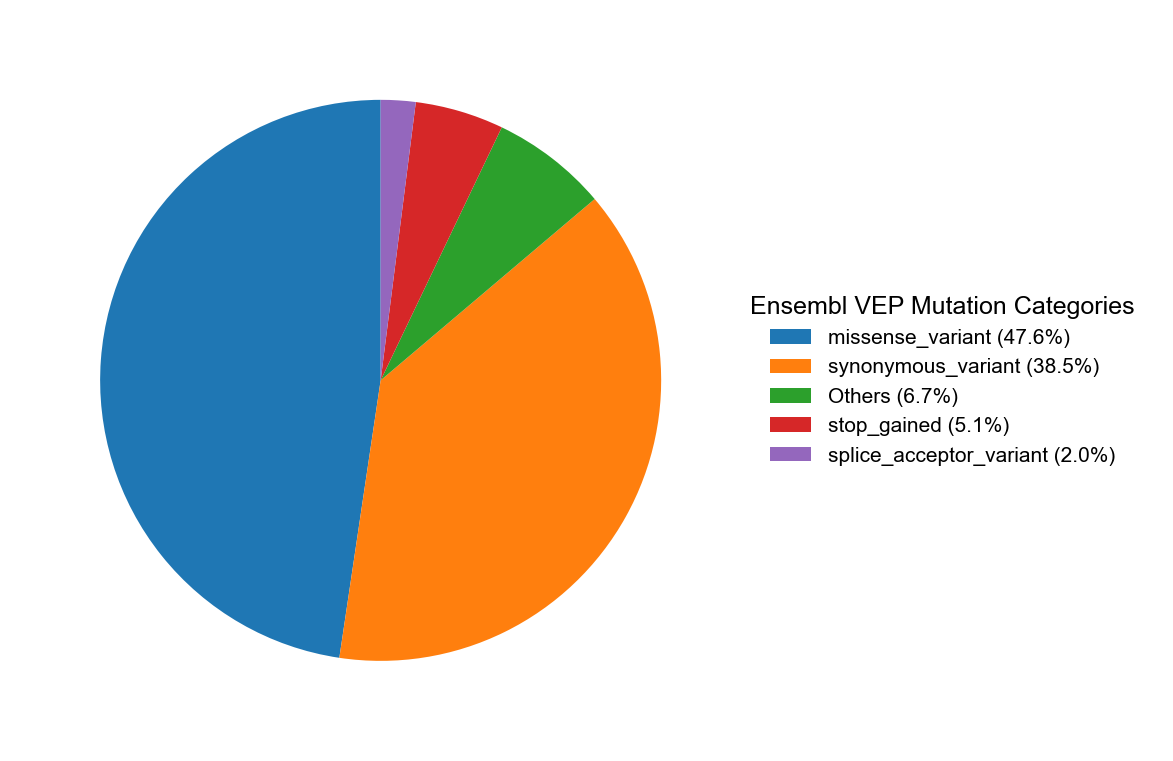

In [10]:
# Ensembl VEP Category Pie Chart

# Ensure numeric type
VEP_mutation_category['Percentage'] = pd.to_numeric(VEP_mutation_category['Percentage'])
VEP_mutation_category['Count'] = pd.to_numeric(VEP_mutation_category['Count'])

# Group categories with <2% into 'Others'
mask_small = VEP_mutation_category['Percentage'] < 2
if mask_small.any():
    others_row = pd.DataFrame({
        'Consequence': ['Others'],
        'Count': [VEP_mutation_category.loc[mask_small, 'Count'].sum()],
        'Percentage': [VEP_mutation_category.loc[mask_small, 'Percentage'].sum()]
    })
    vep_plot_df = pd.concat([VEP_mutation_category.loc[~mask_small], others_row], ignore_index=True)

# Sort by percentage (desc)
vep_plot_df = vep_plot_df.sort_values(by='Percentage', ascending=False)

# Legend labels: "name (xx.x%)"
vep_labels = [f"{row['Consequence']} ({row['Percentage']:.1f}%)"
              for _, row in vep_plot_df.iterrows()]

fig, ax = plt.subplots(figsize=(4,4))
wedges = ax.pie(vep_plot_df['Percentage'], startangle=90)[0]

ax.legend(
    wedges, vep_labels,
    title="Ensembl VEP Mutation Categories",
    title_fontsize=6,
    fontsize=5,
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)
plt.tight_layout()
plt.show()

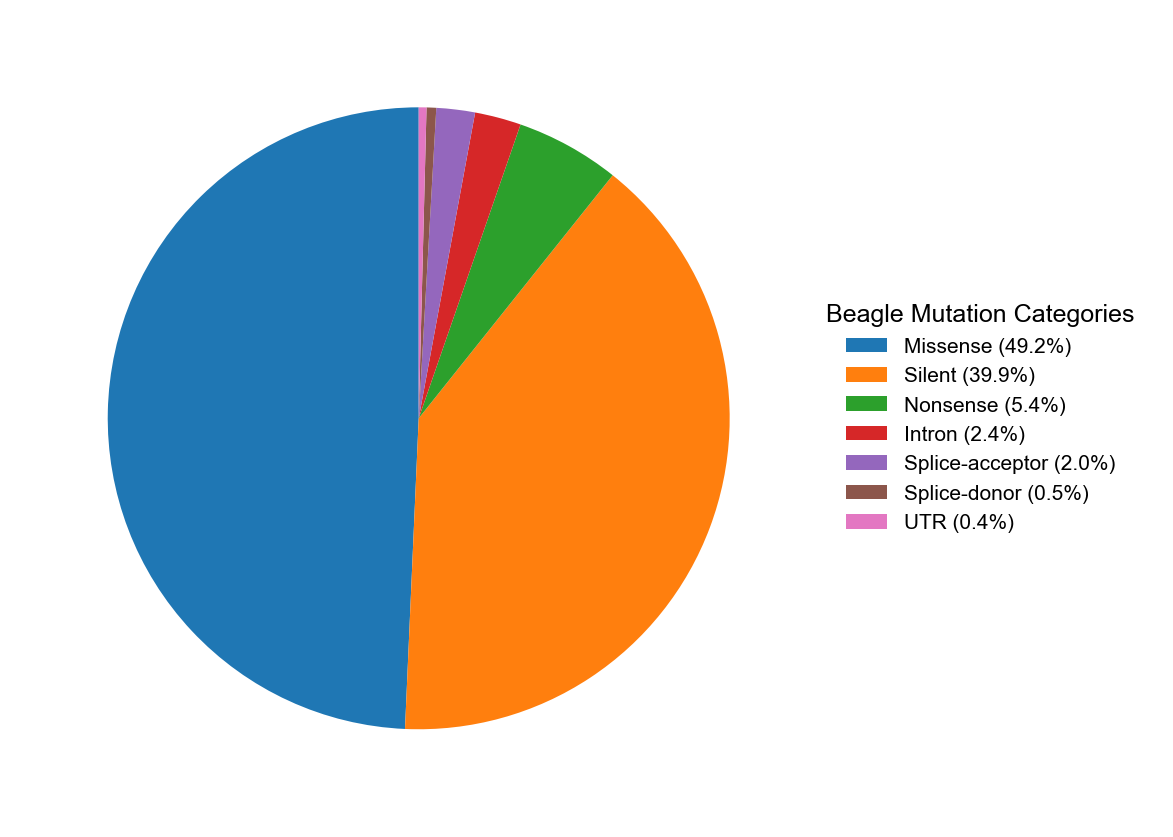

In [11]:
# Beagle Mutation Category Pie Chart
beagle_plot_df = Beagle_mutation_category.copy()

beagle_plot_df['Percentage'] = pd.to_numeric(beagle_plot_df['Percentage'])
beagle_plot_df['Count'] = pd.to_numeric(beagle_plot_df['Count'])

# thr=0 -> No grouping, thr>0 -> Group small categories into 'Others'
thr = 0
if thr and thr > 0:
    mask_small = beagle_plot_df['Percentage'] < thr
    if mask_small.any():
        others_row = pd.DataFrame({
            'Mutation Category': ['Others'],
            'Count': [beagle_plot_df.loc[mask_small, 'Count'].sum()],
            'Percentage': [beagle_plot_df.loc[mask_small, 'Percentage'].sum()],
        })
        beagle_plot_df = pd.concat([beagle_plot_df.loc[~mask_small], others_row], ignore_index=True)

# Sort by percentage (desc)
beagle_plot_df = beagle_plot_df.sort_values(by='Percentage', ascending=False)

# Build legend labels
beagle_labels = [f"{row['Mutation Category']} ({row['Percentage']:.1f}%)"
                 for _, row in beagle_plot_df.iterrows()]

# Plot
fig, ax = plt.subplots(figsize=(4, 4))
wedges = ax.pie(beagle_plot_df['Percentage'], startangle=90)[0]

ax.legend(
    wedges, 
    beagle_labels,
    title="Beagle Mutation Categories", title_fontsize=6, fontsize=5,
    loc="center left", bbox_to_anchor=(1, 0, 0.5, 1)
)
plt.tight_layout()
plt.show()

In [12]:
# Cross-tab between VEP and Beagle categories
crosstab = pd.crosstab(zscores_control_unambiguous_VEPannotated['Consequence'], zscores_control_unambiguous_VEPannotated['Mutation Category'])

# Show table
print(crosstab)

Mutation Category                                   Intron  Missense  \
Consequence                                                            
3_prime_UTR_variant                                      0         0   
5_prime_UTR_variant                                      0         0   
missense_variant                                         0     30145   
missense_variant,splice_region_variant                   0       955   
splice_acceptor_variant                                  0         0   
splice_donor_5th_base_variant,intron_variant           270         0   
splice_donor_region_variant,intron_variant             275         0   
splice_donor_variant                                     0         0   
splice_region_variant,splice_polypyrimidine_tra...     995         0   
splice_region_variant,synonymous_variant                 0         0   
start_lost                                               0        60   
stop_gained                                              0      

In [13]:
VEP_info = pd.DataFrame({
    'dtype': zscores_control_unambiguous_VEPannotated.dtypes,
    'non-null count': zscores_control_unambiguous_VEPannotated.notna().sum(),
    'missing (%)': zscores_control_unambiguous_VEPannotated.isna().mean() * 100,
    'n_unique': zscores_control_unambiguous_VEPannotated.nunique(),
    'example': zscores_control_unambiguous_VEPannotated.apply(lambda col: col.dropna().unique()[:3])
}).sort_values('missing (%)', ascending=True)

print(f'{len(zscores_control_unambiguous_VEPannotated)} rows and {len(zscores_control_unambiguous_VEPannotated.columns)} columns')
VEP_info

63285 rows and 198 columns


,dtype,non-null count,missing (%),n_unique,example
Guide,object,63285,0.000000,12657,"[AAAAAACATCGTAGTAGCAG, AAAAAACTCAACAGCAGTGA, A..."
CADD_RAW,float64,63285,0.000000,9493,"[2.813513, 3.741037, 4.475384]"
hgvs,object,63285,0.000000,9505,"[ENST00000357387.8:c.3325C>T, ENST00000369535...."
Location,object,63285,0.000000,9505,"[5:38950523-38950523, 1:114708594-114708594, 3..."
Allele,object,63285,0.000000,2,"[A, T]"
Consequence,object,63285,0.000000,15,"[missense_variant, synonymous_variant, splice_..."
IMPACT,object,63285,0.000000,4,"[MODERATE, LOW, HIGH]"
Feature_type,object,63285,0.000000,1,[Transcript]
Feature,object,63285,0.000000,28,"[ENST00000357387.8, ENST00000369535.5, ENST000..."
BIOTYPE,object,63285,0.000000,1,[protein_coding]


In [ ]:
VEP_info = pd.DataFrame({
    'dtype': zscores_control_unambiguous_VEPannotated.dtypes,
    'non-null count': zscores_control_unambiguous_VEPannotated.notna().sum(),
    'missing (%)': zscores_control_unambiguous_VEPannotated.isna().mean() * 100,
    'n_unique': zscores_control_unambiguous_VEPannotated.nunique(),
    'example': zscores_control_unambiguous_VEPannotated.apply(lambda col: col.dropna().unique()[:3])
}).sort_values('missing (%)', ascending=True)

print(f'{len(zscores_control_unambiguous_VEPannotated)} rows and {len(zscores_control_unambiguous_VEPannotated.columns)} columns')
VEP_info

## Checking Alpha Missense Agreement between Ensembl and dbSNP

In [14]:
df_amscore = zscores_control_unambiguous_VEPannotated.dropna(subset=["am_pathogenicity",  "AlphaMissense_score"])
r = df_amscore["am_pathogenicity"].corr(df_amscore[ "AlphaMissense_score"])
n= len(df_amscore)

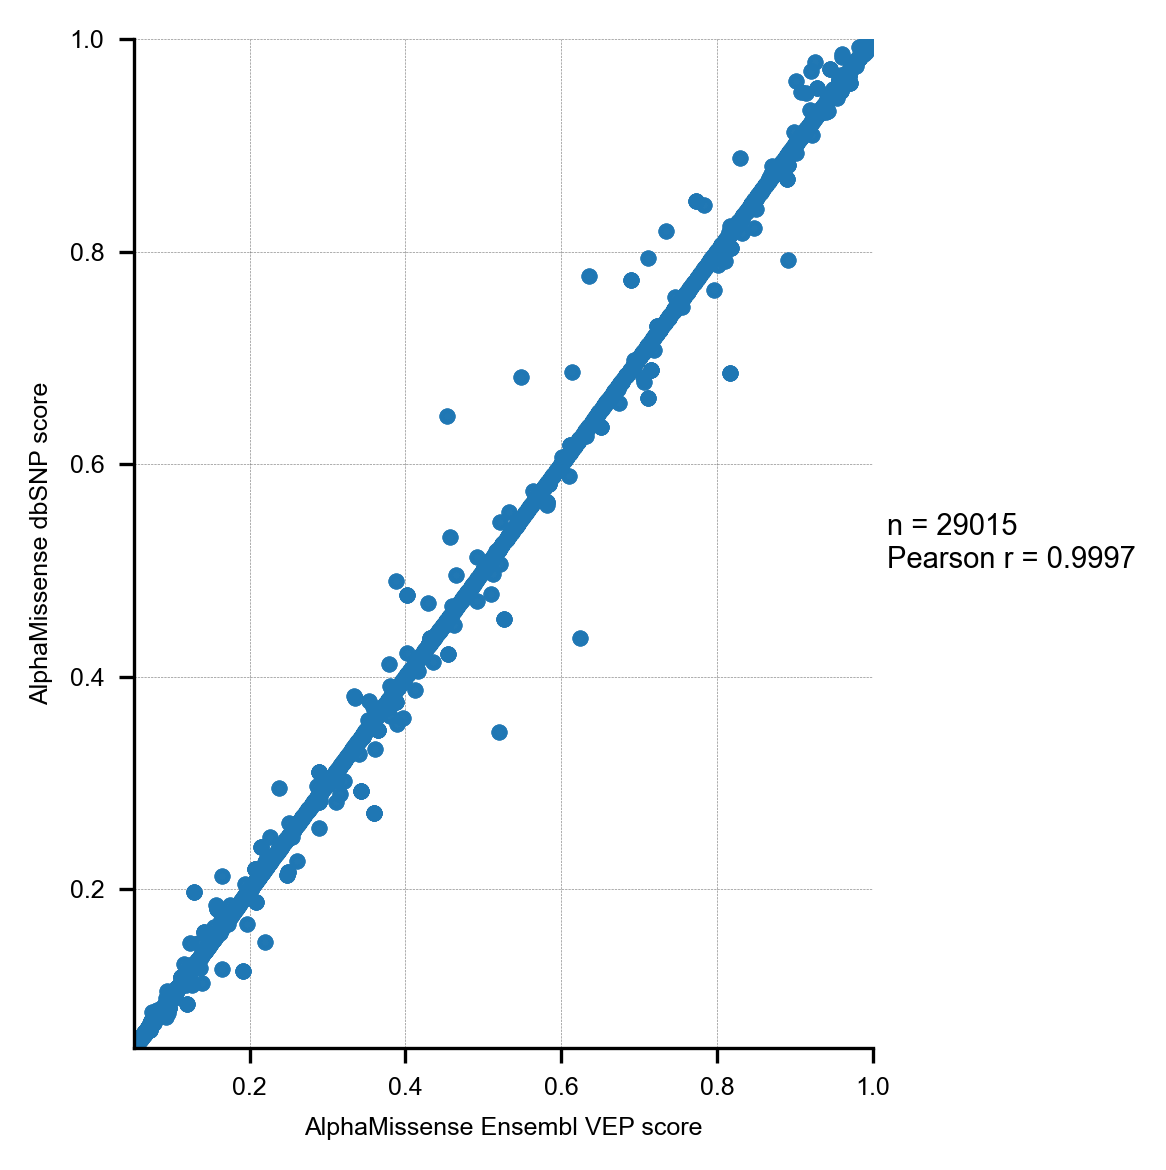

In [15]:
# Scatter plot with Pearson correlation
fig, ax = plt.subplots(figsize=(4,4))

ax.scatter(
    df_amscore["am_pathogenicity"],
    df_amscore["AlphaMissense_score"],
    s=8, alpha=0.6
)

lims = [
    min(df_amscore["am_pathogenicity"].min(), df_amscore["AlphaMissense_score"].min()),
    max(df_amscore["am_pathogenicity"].max(), df_amscore["AlphaMissense_score"].max())
]

ax.plot(lims, lims, "--")
ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_xlabel("AlphaMissense Ensembl VEP score", fontsize=6)
ax.set_ylabel("AlphaMissense dbSNP score", fontsize=6)


ax.text(1.02, 0.5, f"n = {n}\nPearson r = {r:.4f}",
        transform=ax.transAxes, va="center", fontsize=7)

plt.tight_layout()
plt.show()

## Missigness Analysis

#### Heatmap

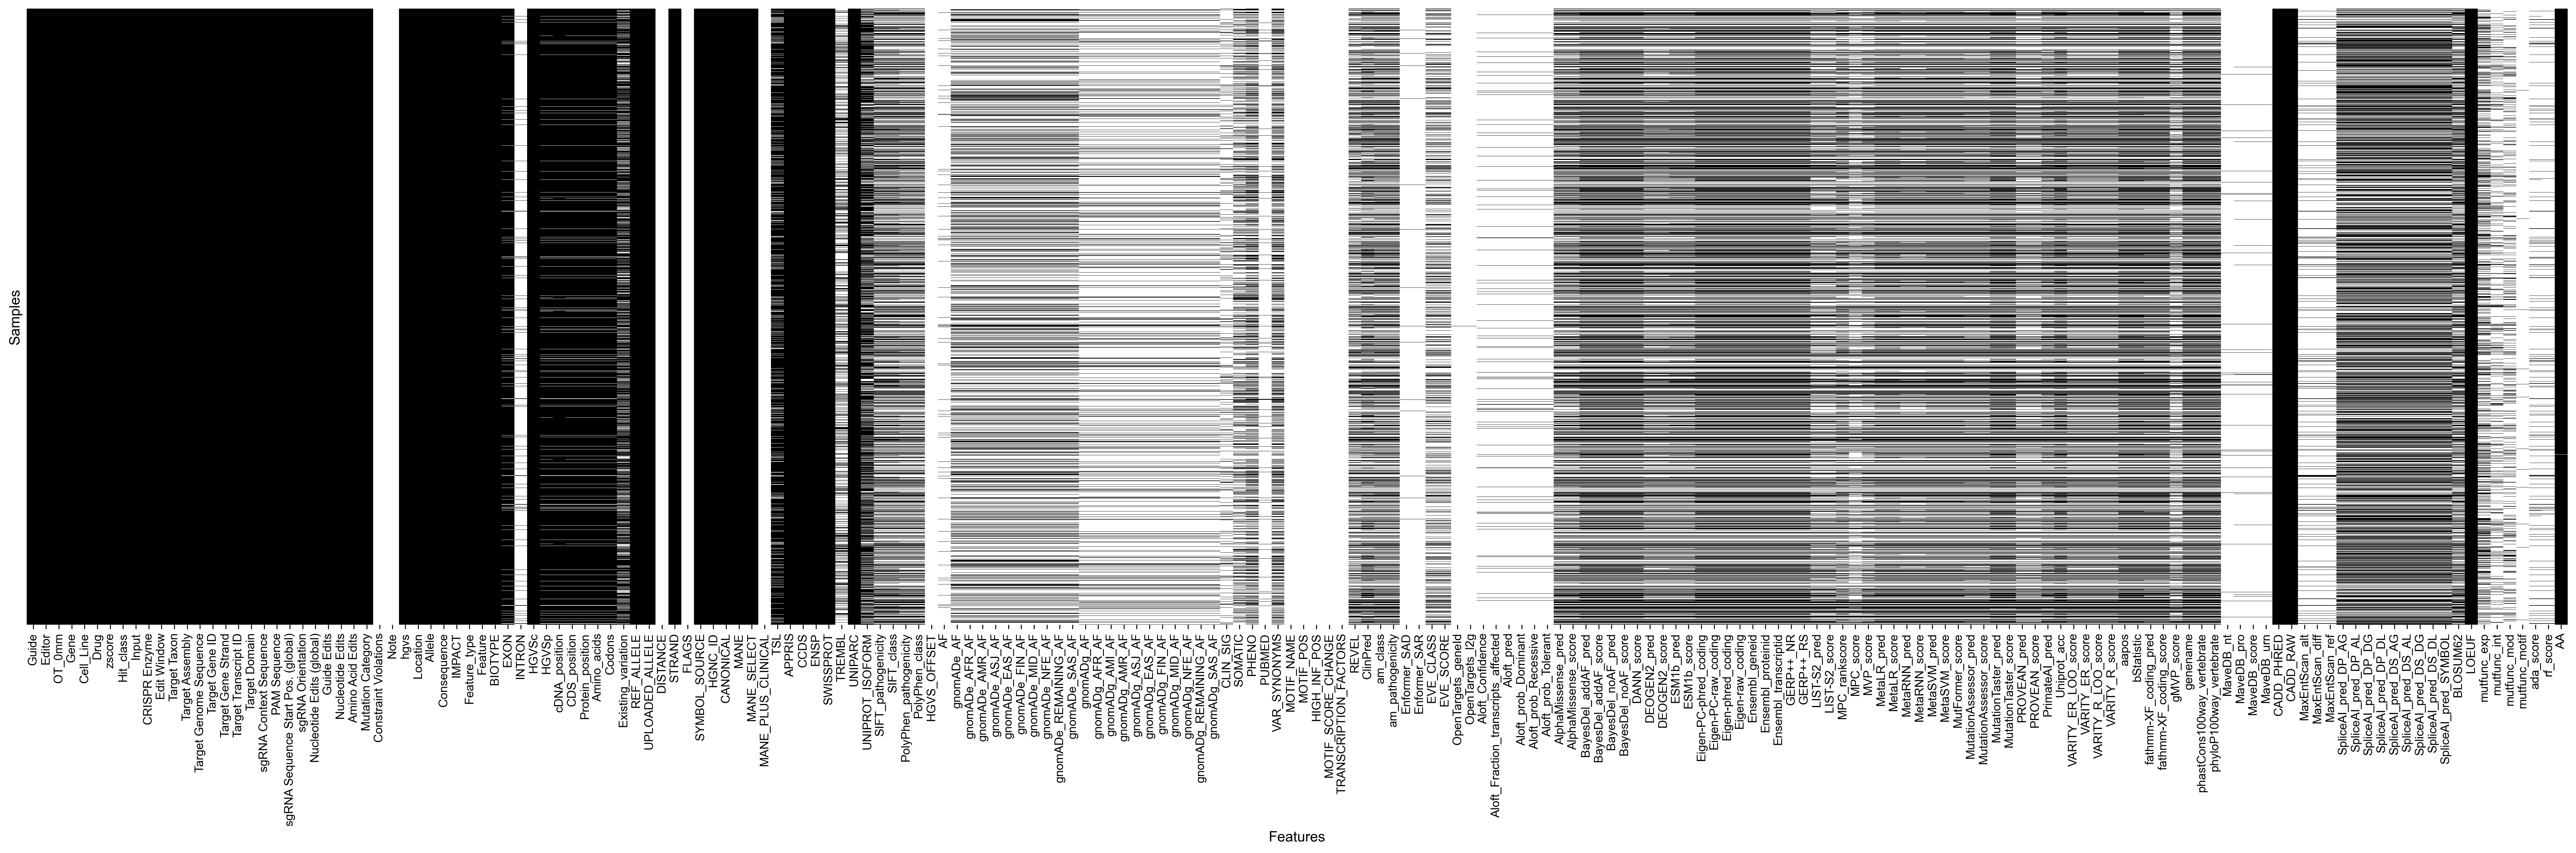

In [16]:
plt.figure(figsize=(30, 10))

sns.heatmap(
    zscores_control_unambiguous_VEPannotated.isnull(),
    cbar=False,
    cmap='binary_r'
)

#plt.title("Missing Values Heatmap", fontsize=16)
plt.xlabel("Features", fontsize=12)
plt.ylabel("Samples", fontsize=12)
plt.xticks(rotation=90, fontsize=10)
plt.yticks([])  # Hide sample indices
plt.tight_layout()
plt.show()

#### Missingness Histogram

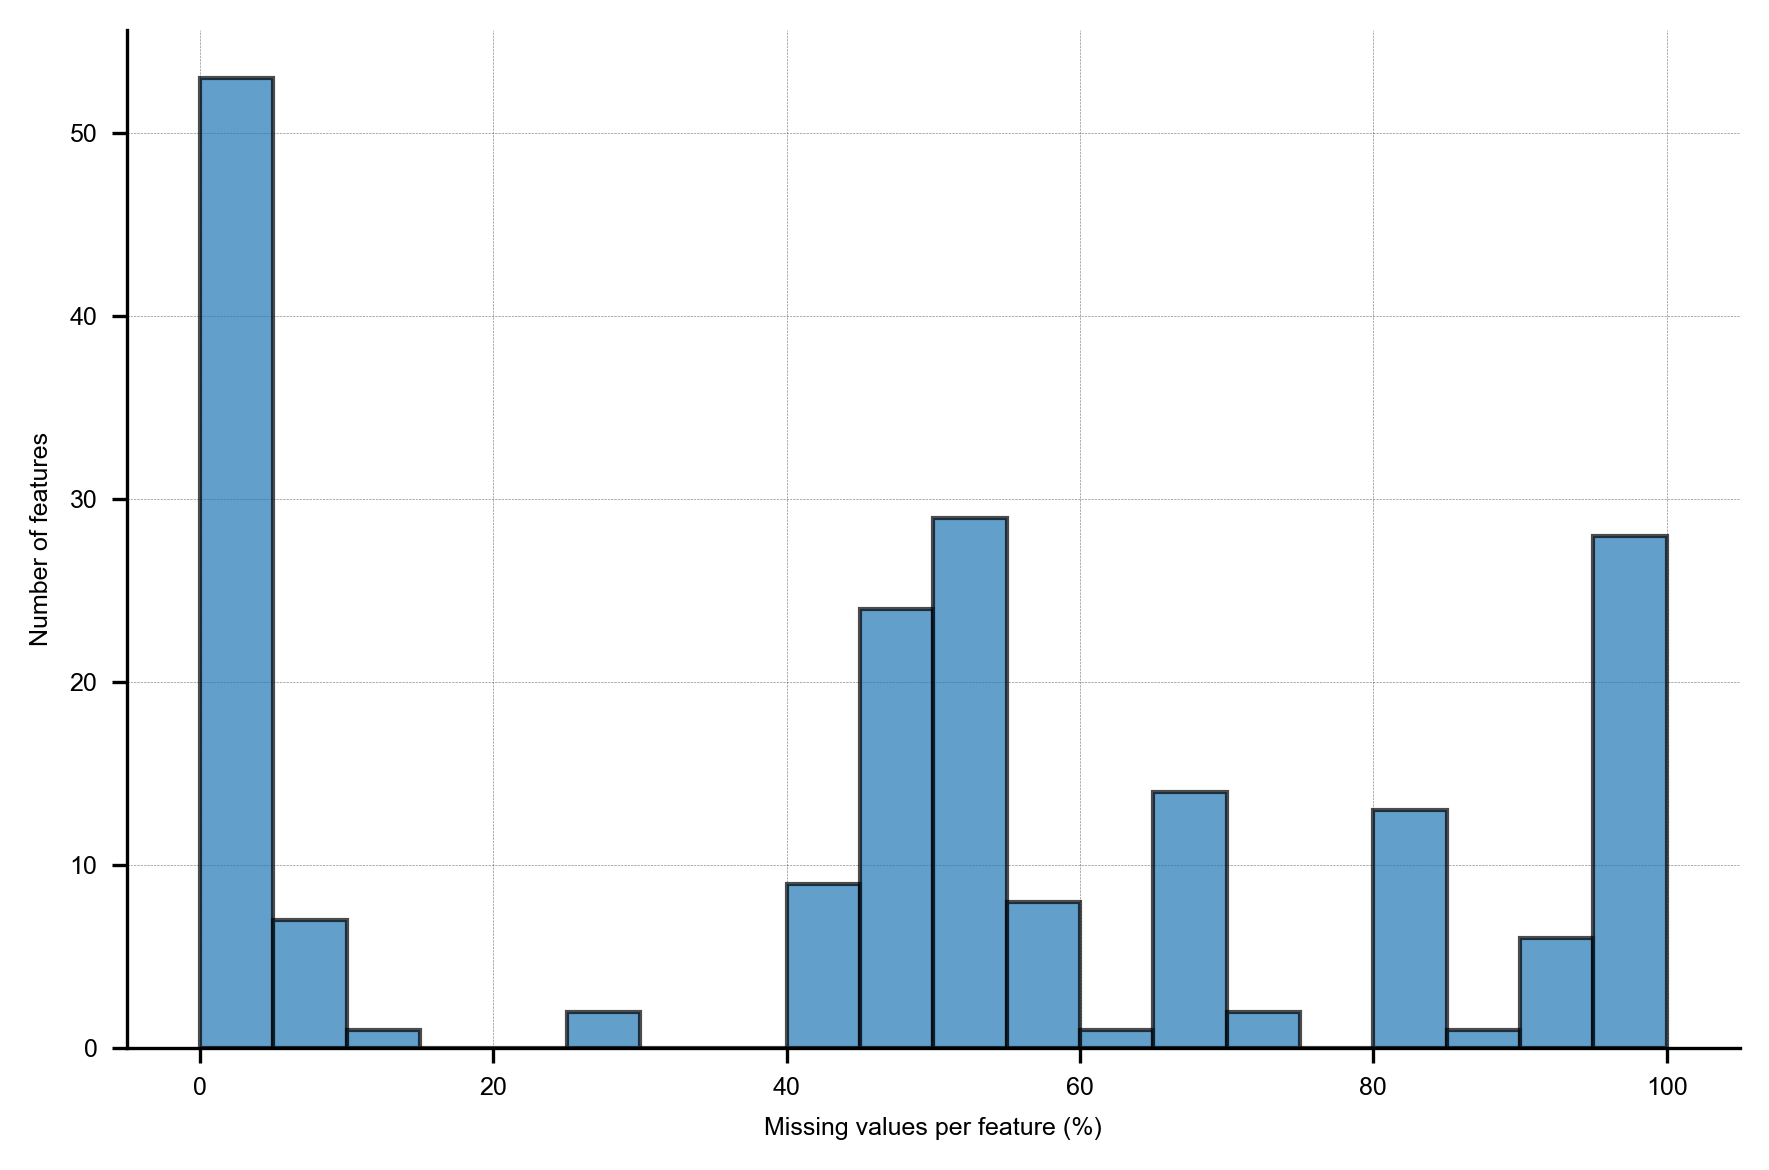

In [17]:

# Calculate percentage of missing values per column
missing_percent = zscores_control_unambiguous_VEPannotated.isna().mean() * 100

# Plot histogram
plt.figure(figsize=(6,4))
plt.hist(missing_percent, bins=20, edgecolor="black", alpha=0.7)

plt.xlabel("Missing values per feature (%)", fontsize=6)
plt.ylabel("Number of features", fontsize=6)


plt.tight_layout()
plt.show()

# Also print the features sorted by missingness
#missing_percent.sort_values(ascending=False)

#### Analyze feature's missing data per mutation category

In [10]:
missing_perc = zscores_control_unambiguous_VEPannotated.isna().mean() * 100  

# Select features in the 40–60% cluster
cluster_feats = missing_perc[(missing_perc >= 40) & (missing_perc <= 60)].index.tolist()
print("Features in 40–60% missingness cluster:\n", cluster_feats)

# Check missingness distribution of these features across mutation categories
for feat in cluster_feats:
    print(f"\n=== {feat} (overall missing: {missing_perc[feat]:.2f}%) ===")
    summary = (
        zscores_control_unambiguous_VEPannotated.groupby("Mutation Category")[feat]
          .apply(lambda x: x.isna().mean() * 100)
          .sort_values(ascending=False)
    )
    print(summary)

Features in 40–60% missingness cluster:
 ['SIFT_pathogenicity', 'SIFT_class', 'PolyPhen_pathogenicity', 'PolyPhen_class', 'PHENO', 'VAR_SYNONYMS', 'REVEL', 'ClinPred', 'am_class', 'am_pathogenicity', 'AlphaMissense_pred', 'AlphaMissense_score', 'BayesDel_addAF_pred', 'BayesDel_addAF_score', 'BayesDel_noAF_pred', 'BayesDel_noAF_score', 'DANN_score', 'DEOGEN2_pred', 'DEOGEN2_score', 'ESM1b_pred', 'ESM1b_score', 'Eigen-PC-phred_coding', 'Eigen-PC-raw_coding', 'Eigen-phred_coding', 'Eigen-raw_coding', 'Ensembl_geneid', 'Ensembl_proteinid', 'Ensembl_transcriptid', 'GERP++_NR', 'GERP++_RS', 'LIST-S2_pred', 'LIST-S2_score', 'MPC_rankscore', 'MVP_score', 'MetaLR_pred', 'MetaLR_score', 'MetaRNN_pred', 'MetaRNN_score', 'MetaSVM_pred', 'MetaSVM_score', 'MutFormer_score', 'MutationAssessor_pred', 'MutationAssessor_score', 'MutationTaster_pred', 'MutationTaster_score', 'PROVEAN_pred', 'PROVEAN_score', 'PrimateAI_pred', 'Uniprot_acc', 'VARITY_ER_LOO_score', 'VARITY_ER_score', 'VARITY_R_LOO_score', '

In [11]:
missing_perc = zscores_control_unambiguous_VEPannotated.isna().mean() * 100  

# Select features in the cluster
cluster_feats = missing_perc[(missing_perc >= 60) & (missing_perc <= 80)].index.tolist()
print("Features in 60–80% missingness cluster:\n", cluster_feats)

# Check missingness distribution of these features across mutation categories
for feat in cluster_feats:
    print(f"\n=== {feat} (overall missing: {missing_perc[feat]:.2f}%) ===")
    summary = (
        zscores_control_unambiguous_VEPannotated.groupby("Mutation Category")[feat]
          .apply(lambda x: x.isna().mean() * 100)
          .sort_values(ascending=False)
    )
    print(summary)

Features in 60–80% missingness cluster:
 ['TREMBL', 'gnomADe_AF', 'gnomADe_AFR_AF', 'gnomADe_AMR_AF', 'gnomADe_ASJ_AF', 'gnomADe_EAS_AF', 'gnomADe_FIN_AF', 'gnomADe_MID_AF', 'gnomADe_NFE_AF', 'gnomADe_REMAINING_AF', 'gnomADe_SAS_AF', 'SOMATIC', 'EVE_CLASS', 'EVE_SCORE', 'MPC_score', 'gMVP_score', 'mutfunc_exp', 'mutfunc_mod']

=== TREMBL (overall missing: 67.75%) ===
Mutation Category
Missense           71.749784
Splice-donor       69.863014
Nonsense           68.079470
Silent             63.400320
Splice-acceptor    62.867647
Intron             62.264151
UTR                57.812500
Name: TREMBL, dtype: float64

=== gnomADe_AF (overall missing: 66.77%) ===
Mutation Category
Splice-acceptor    94.852941
Nonsense           77.350993
Splice-donor       75.342466
Missense           67.382531
Silent             63.738218
Intron             57.861635
UTR                56.250000
Name: gnomADe_AF, dtype: float64

=== gnomADe_AFR_AF (overall missing: 66.77%) ===
Mutation Category
Splice-accep

In [12]:
missing_perc = zscores_control_unambiguous_VEPannotated.isna().mean() * 100  

# Select features in the 80–100% cluster
cluster_feats = missing_perc[(missing_perc >= 80) & (missing_perc <= 100)].index.tolist()
print("Features in 80–100% missingness cluster:\n", cluster_feats)

# Check missingness distribution of these features across mutation categories
for feat in cluster_feats:
    print(f"\n=== {feat} (overall missing: {missing_perc[feat]:.2f}%) ===")
    summary = (
        zscores_control_unambiguous_VEPannotated.groupby("Mutation Category")[feat]
          .apply(lambda x: x.isna().mean() * 100)
          .sort_values(ascending=False)
    )
    print(summary)

Features in 80–100% missingness cluster:
 ['Source', 'Constraint Violations', 'Note', 'INTRON', 'DISTANCE', 'FLAGS', 'MANE_PLUS_CLINICAL', 'HGVS_OFFSET', 'AF', 'gnomADg_AF', 'gnomADg_AFR_AF', 'gnomADg_AMI_AF', 'gnomADg_AMR_AF', 'gnomADg_ASJ_AF', 'gnomADg_EAS_AF', 'gnomADg_FIN_AF', 'gnomADg_MID_AF', 'gnomADg_NFE_AF', 'gnomADg_REMAINING_AF', 'gnomADg_SAS_AF', 'CLIN_SIG', 'PUBMED', 'MOTIF_NAME', 'MOTIF_POS', 'HIGH_INF_POS', 'MOTIF_SCORE_CHANGE', 'TRANSCRIPTION_FACTORS', 'Enformer_SAD', 'Enformer_SAR', 'OpenTargets_geneId', 'OpenTargets_l2g', 'Aloft_Confidence', 'Aloft_Fraction_transcripts_affected', 'Aloft_pred', 'Aloft_prob_Dominant', 'Aloft_prob_Recessive', 'Aloft_prob_Tolerant', 'MaveDB_nt', 'MaveDB_pro', 'MaveDB_score', 'MaveDB_urn', 'MaxEntScan_alt', 'MaxEntScan_diff', 'MaxEntScan_ref', 'mutfunc_int', 'mutfunc_motif', 'ada_score', 'rf_score']

=== Source (overall missing: 100.00%) ===
Mutation Category
Intron             100.0
Missense           100.0
Nonsense           100.0
Silent 

# Drop genomAD_ features

In [18]:
#Check which columns will be dropped
cols_gnomAD_all = [c for c in zscores_control_unambiguous_VEPannotated.columns
                   if c.startswith('gnomADe_') or c.startswith('gnomADg_')]
print(f"{len(cols_gnomAD_all)} gnomAD columns to drop")
cols_gnomAD_all

21 gnomAD columns to drop


['gnomADe_AF',
 'gnomADe_AFR_AF',
 'gnomADe_AMR_AF',
 'gnomADe_ASJ_AF',
 'gnomADe_EAS_AF',
 'gnomADe_FIN_AF',
 'gnomADe_MID_AF',
 'gnomADe_NFE_AF',
 'gnomADe_REMAINING_AF',
 'gnomADe_SAS_AF',
 'gnomADg_AF',
 'gnomADg_AFR_AF',
 'gnomADg_AMI_AF',
 'gnomADg_AMR_AF',
 'gnomADg_ASJ_AF',
 'gnomADg_EAS_AF',
 'gnomADg_FIN_AF',
 'gnomADg_MID_AF',
 'gnomADg_NFE_AF',
 'gnomADg_REMAINING_AF',
 'gnomADg_SAS_AF']

In [20]:
# Drop gnomAD columns for control
zscores_control_unambiguous_VEPannotated_processed = zscores_control_unambiguous_VEPannotated.drop(columns=cols_gnomAD_all)

In [21]:
#Check missing values again
VEP_info_processed = pd.DataFrame({
    'dtype': zscores_control_unambiguous_VEPannotated_processed.dtypes,
    'non-null count': zscores_control_unambiguous_VEPannotated_processed.notna().sum(),
    'missing (%)': zscores_control_unambiguous_VEPannotated_processed.isna().mean() * 100,
    'n_unique': zscores_control_unambiguous_VEPannotated_processed.nunique(),
    'example': zscores_control_unambiguous_VEPannotated_processed.apply(lambda col: col.dropna().unique()[:3])
}).sort_values('missing (%)', ascending=True)

print(f'{len(zscores_control_unambiguous_VEPannotated_processed)} rows and {len(zscores_control_unambiguous_VEPannotated_processed.columns)} columns')
VEP_info_processed

63285 rows and 177 columns


,dtype,non-null count,missing (%),n_unique,example
Guide,object,63285,0.000000,12657,"[AAAAAACATCGTAGTAGCAG, AAAAAACTCAACAGCAGTGA, A..."
CADD_RAW,float64,63285,0.000000,9493,"[2.813513, 3.741037, 4.475384]"
hgvs,object,63285,0.000000,9505,"[ENST00000357387.8:c.3325C>T, ENST00000369535...."
Location,object,63285,0.000000,9505,"[5:38950523-38950523, 1:114708594-114708594, 3..."
Allele,object,63285,0.000000,2,"[A, T]"
Consequence,object,63285,0.000000,15,"[missense_variant, synonymous_variant, splice_..."
IMPACT,object,63285,0.000000,4,"[MODERATE, LOW, HIGH]"
Feature_type,object,63285,0.000000,1,[Transcript]
Feature,object,63285,0.000000,28,"[ENST00000357387.8, ENST00000369535.5, ENST000..."
BIOTYPE,object,63285,0.000000,1,[protein_coding]


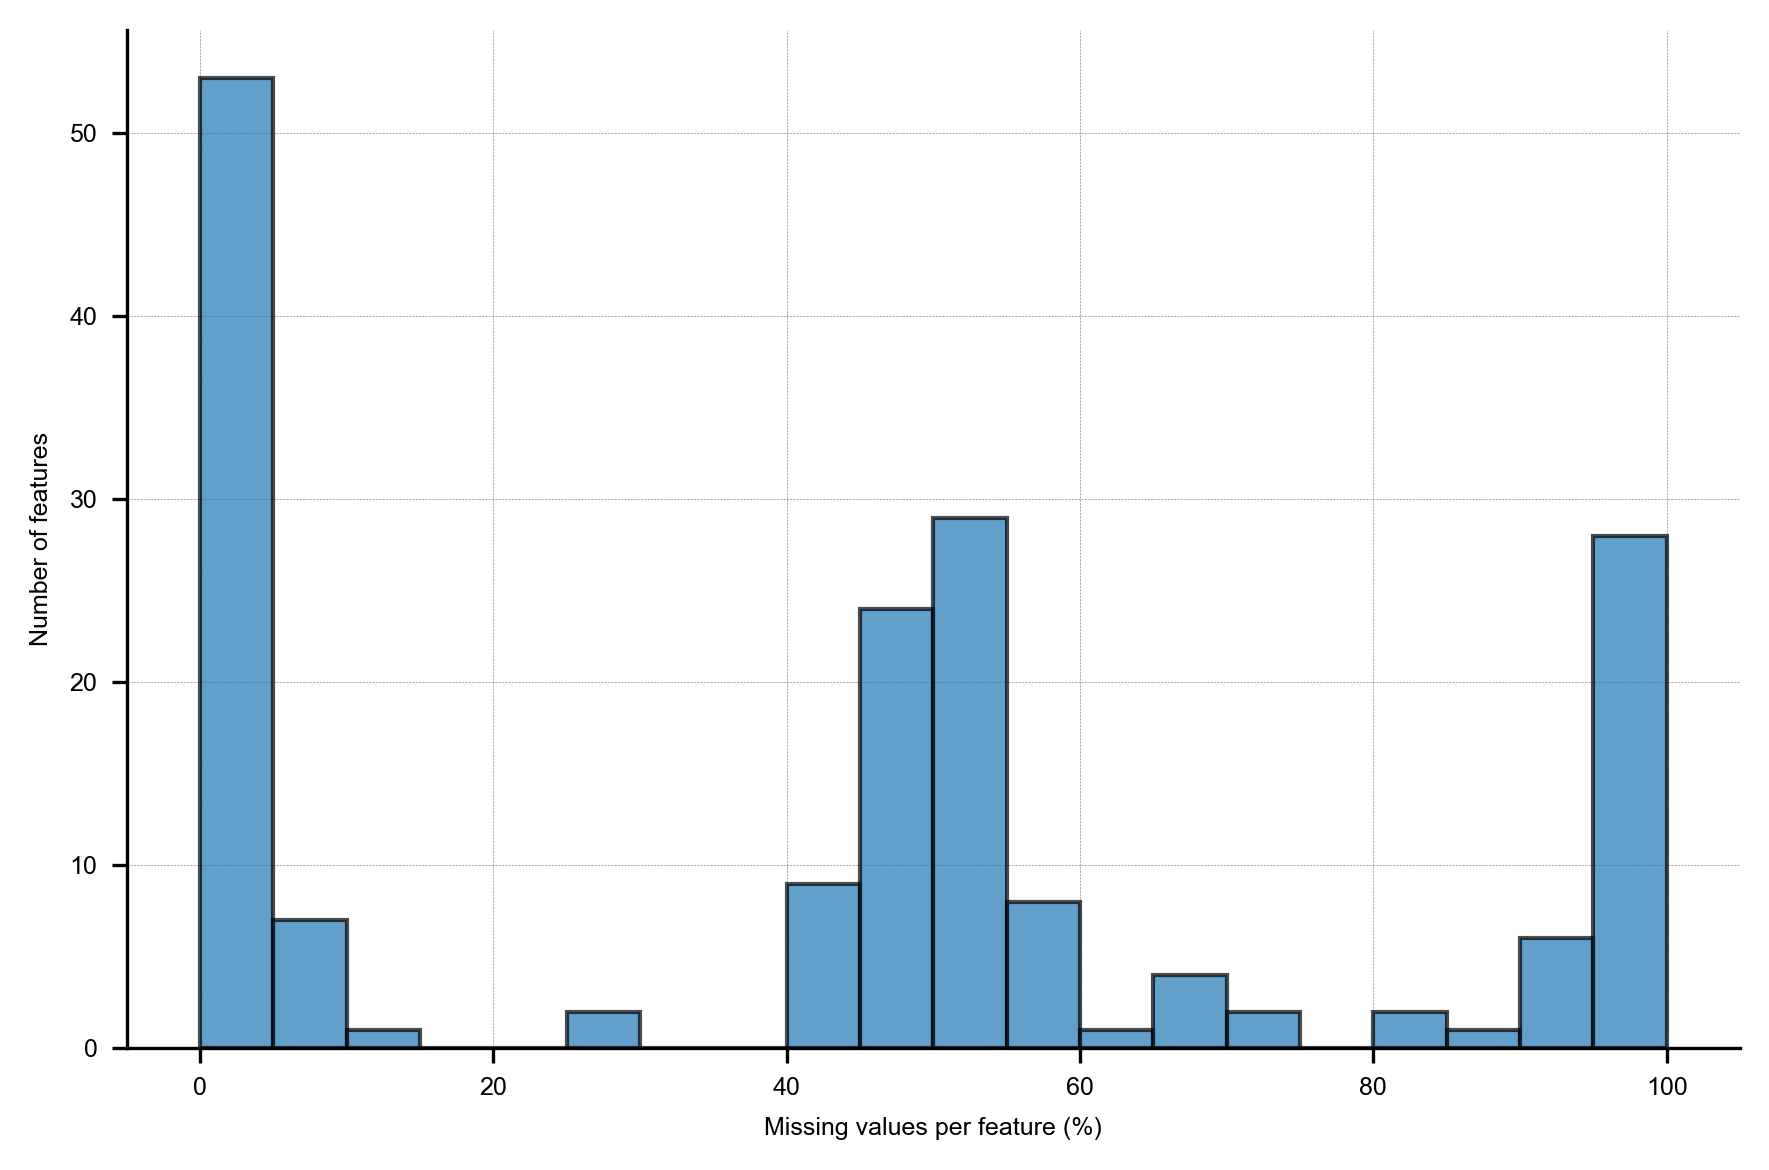

In [22]:
# Calculate percentage of missing values per column
missing_percent = zscores_control_unambiguous_VEPannotated_processed.isna().mean() * 100

# Plot histogram
plt.figure(figsize=(6,4))
plt.hist(missing_percent, bins=20, edgecolor="black", alpha=0.7)

plt.xlabel("Missing values per feature (%)", fontsize=6)
plt.ylabel("Number of features", fontsize=6)

# Example threshold line at 30%
#plt.axvline(30, color="red", linestyle="--", label="30% threshold")
#plt.legend()

plt.tight_layout()
plt.show()

# Drop features with >75% of missing data

In [23]:
def drop_missing_features(df, threshold=75, keep_columns=None):
    """
    Drops columns from df with missingness > threshold,
    except those listed in keep_cols.
    """
    if keep_columns is None:
        keep_columns = []
    
    missing_data_percentage = df.isna().mean() * 100
    cols_to_drop = [
        col for col in missing_data_percentage.index
        if (missing_data_percentage[col] > threshold) and (col not in keep_columns)
    ]
    return df.drop(columns=cols_to_drop), cols_to_drop

In [24]:
# Features to keep even if above threshold (splice-related)
features_to_keep = [
    "Source",
    "rf_score",
    "ada_score",
    "MaxEntScan_ref",
    "MaxEntScan_alt",
    "MaxEntScan_diff"
]

# Drop features with more than 75% missing values, except features to keep 
zscores_control_unambiguous_VEPannotated_processed, dropped_features = drop_missing_features(zscores_control_unambiguous_VEPannotated_processed, threshold=75, keep_columns=features_to_keep)

In [25]:
print(f"Dropped {len(dropped_features)} features with >75% missing values (except splice-related):")
print(dropped_features)
print(f"Remaining features: {len(zscores_control_unambiguous_VEPannotated_processed.columns)}")

Dropped 32 features with >75% missing values (except splice-related):
['Constraint Violations', 'Note', 'INTRON', 'DISTANCE', 'FLAGS', 'MANE_PLUS_CLINICAL', 'HGVS_OFFSET', 'AF', 'CLIN_SIG', 'PUBMED', 'MOTIF_NAME', 'MOTIF_POS', 'HIGH_INF_POS', 'MOTIF_SCORE_CHANGE', 'TRANSCRIPTION_FACTORS', 'Enformer_SAD', 'Enformer_SAR', 'OpenTargets_geneId', 'OpenTargets_l2g', 'Aloft_Confidence', 'Aloft_Fraction_transcripts_affected', 'Aloft_pred', 'Aloft_prob_Dominant', 'Aloft_prob_Recessive', 'Aloft_prob_Tolerant', 'MaveDB_nt', 'MaveDB_pro', 'MaveDB_score', 'MaveDB_urn', 'mutfunc_int', 'mutfunc_mod', 'mutfunc_motif']
Remaining features: 145


# Drop other columns not useful for classification

In [50]:
cols_to_drop = [
    # Identifiers
    'hgvs', 'hgvs ProtVar', 'Location', 'Allele', 'Feature_type', 'UNIPARC', 'SWISSPROT', 'ENSP', 'CCDS', 'MANE_SELECT', 'MANE', 'CANONICAL',
    'REF_ALLELE', 'UPLOADED_ALLELE', 'STRAND', 'HGVSc', 'SYMBOL_SOURCE', 'Nucleotide Edits', 'Target Taxon', 'Target Assembly',	'Target Gene ID',
    'Target Gene Strand', 'Target Domain', 'Nucleotide Edits (global)', 'Guide Edits', 'Target Genome Sequence', 'HGNC_ID', 'AA', 'EXON', 
    'cDNA_position', 'HGVSp', 'CDS_position', 'Codons', 'Amino_acids', 'Protein_position', 'Existing_variation', 'UNIPROT_ISOFORM', 'aapos',
    'Uniprot_acc', 'Ensembl_transcriptid', 'Ensembl_proteinid', 'genename', 'Ensembl_geneid', 'SpliceAI_pred_SYMBOL', 'VAR_SYNONYMS', 'TREMBL',
    'MaveDB_urn', 'MaveDB_pro', 'MaveDB_nt', 'INTRON', 'PUBMED', 'Aloft_Fraction_transcripts_affected', 'Constraint Violations', 
    'OpenTargets_geneId', 'Feature', 'APPRIS', 'Input',

    #Categorical label of scores
    'BayesDel_noAF_pred', 'BayesDel_addAF_pred', 'MutationTaster_pred', 'fathmm-XF_coding_pred', 'SIFT_class', 'MetaLR_pred', 'MetaSVM_pred',
    'MetaRNN_pred', 'AlphaMissense_pred', 'ESM1b_pred', 'PolyPhen_class', 'am_class', 'MutationAssessor_pred', 'DEOGEN2_pred', 'LIST-S2_pred',
    'PROVEAN_pred', 'EVE_CLASS',

    #Experimental data
    'CRISPR Enzyme', 'Edit Window', 'sgRNA Context Sequence', 'sgRNA Sequence Start Pos. (global)', 'sgRNA Orientation', 'PAM Sequence',

    #Other
    'PHENO', 'SOMATIC', 'MutationTaster_score', 'BIOTYPE',

    # Drop mutation category from Ensembl VEP annotations (we keep Beagle's)
    'Consequence'
]


meta_cols=[
    'Target Transcript ID', 'RefSeq match transcript (MANE Select)', 'Guide', 'Editor', 'Gene', 'Cell_Line','Drug', 'Amino Acid Edits', 
    'Source', 'Hit_class', 'OT_0mm'
]

#don't forget to take the zscores from the training set

In [40]:
#Drop the columns to drop 
zscores_control_unambiguous_VEPannotated_processed = zscores_control_unambiguous_VEPannotated_processed.drop(columns=cols_to_drop, errors='ignore')
#Print the shape of the processed dataset
print(f'Shape of the processed dataset: {zscores_control_unambiguous_VEPannotated_processed.shape}')

Shape of the processed dataset: (63285, 69)


In [41]:
#Check missing values again
VEP_info_processed = pd.DataFrame({
    'dtype': zscores_control_unambiguous_VEPannotated_processed.dtypes,
    'non-null count': zscores_control_unambiguous_VEPannotated_processed.notna().sum(),
    'missing (%)': zscores_control_unambiguous_VEPannotated_processed.isna().mean() * 100,
    'n_unique': zscores_control_unambiguous_VEPannotated_processed.nunique(),
    'example': zscores_control_unambiguous_VEPannotated_processed.apply(lambda col: col.dropna().unique()[:3])
}).sort_values('missing (%)', ascending=True)

print(f'{len(zscores_control_unambiguous_VEPannotated_processed)} rows and {len(zscores_control_unambiguous_VEPannotated_processed.columns)} columns')
VEP_info_processed

63285 rows and 69 columns


,dtype,non-null count,missing (%),n_unique,example
Guide,object,63285,0.000000,12657,"[AAAAAACATCGTAGTAGCAG, AAAAAACTCAACAGCAGTGA, A..."
CADD_PHRED,float64,63285,0.000000,2848,"[20.4, 23.4, 25.4]"
LOEUF,float64,63285,0.000000,28,"[0.305, 0.55, 0.319]"
CADD_RAW,float64,63285,0.000000,9493,"[2.813513, 3.741037, 4.475384]"
Mutation Category,object,63285,0.000000,7,"[Missense, Silent, Splice-acceptor]"
Amino Acid Edits,object,63285,0.000000,8026,"[His1109Tyr, Leu171Phe, Thr930Ile]"
Target Transcript ID,object,63285,0.000000,28,"[ENST00000357387.8, ENST00000369535.5, ENST000..."
IMPACT,object,63285,0.000000,4,"[MODERATE, LOW, HIGH]"
zscore,float64,63285,0.000000,63152,"[0.2382350673768793, 0.4182056717224319, 0.371..."
Drug,object,63285,0.000000,3,"[PIC, SCH, LIN]"


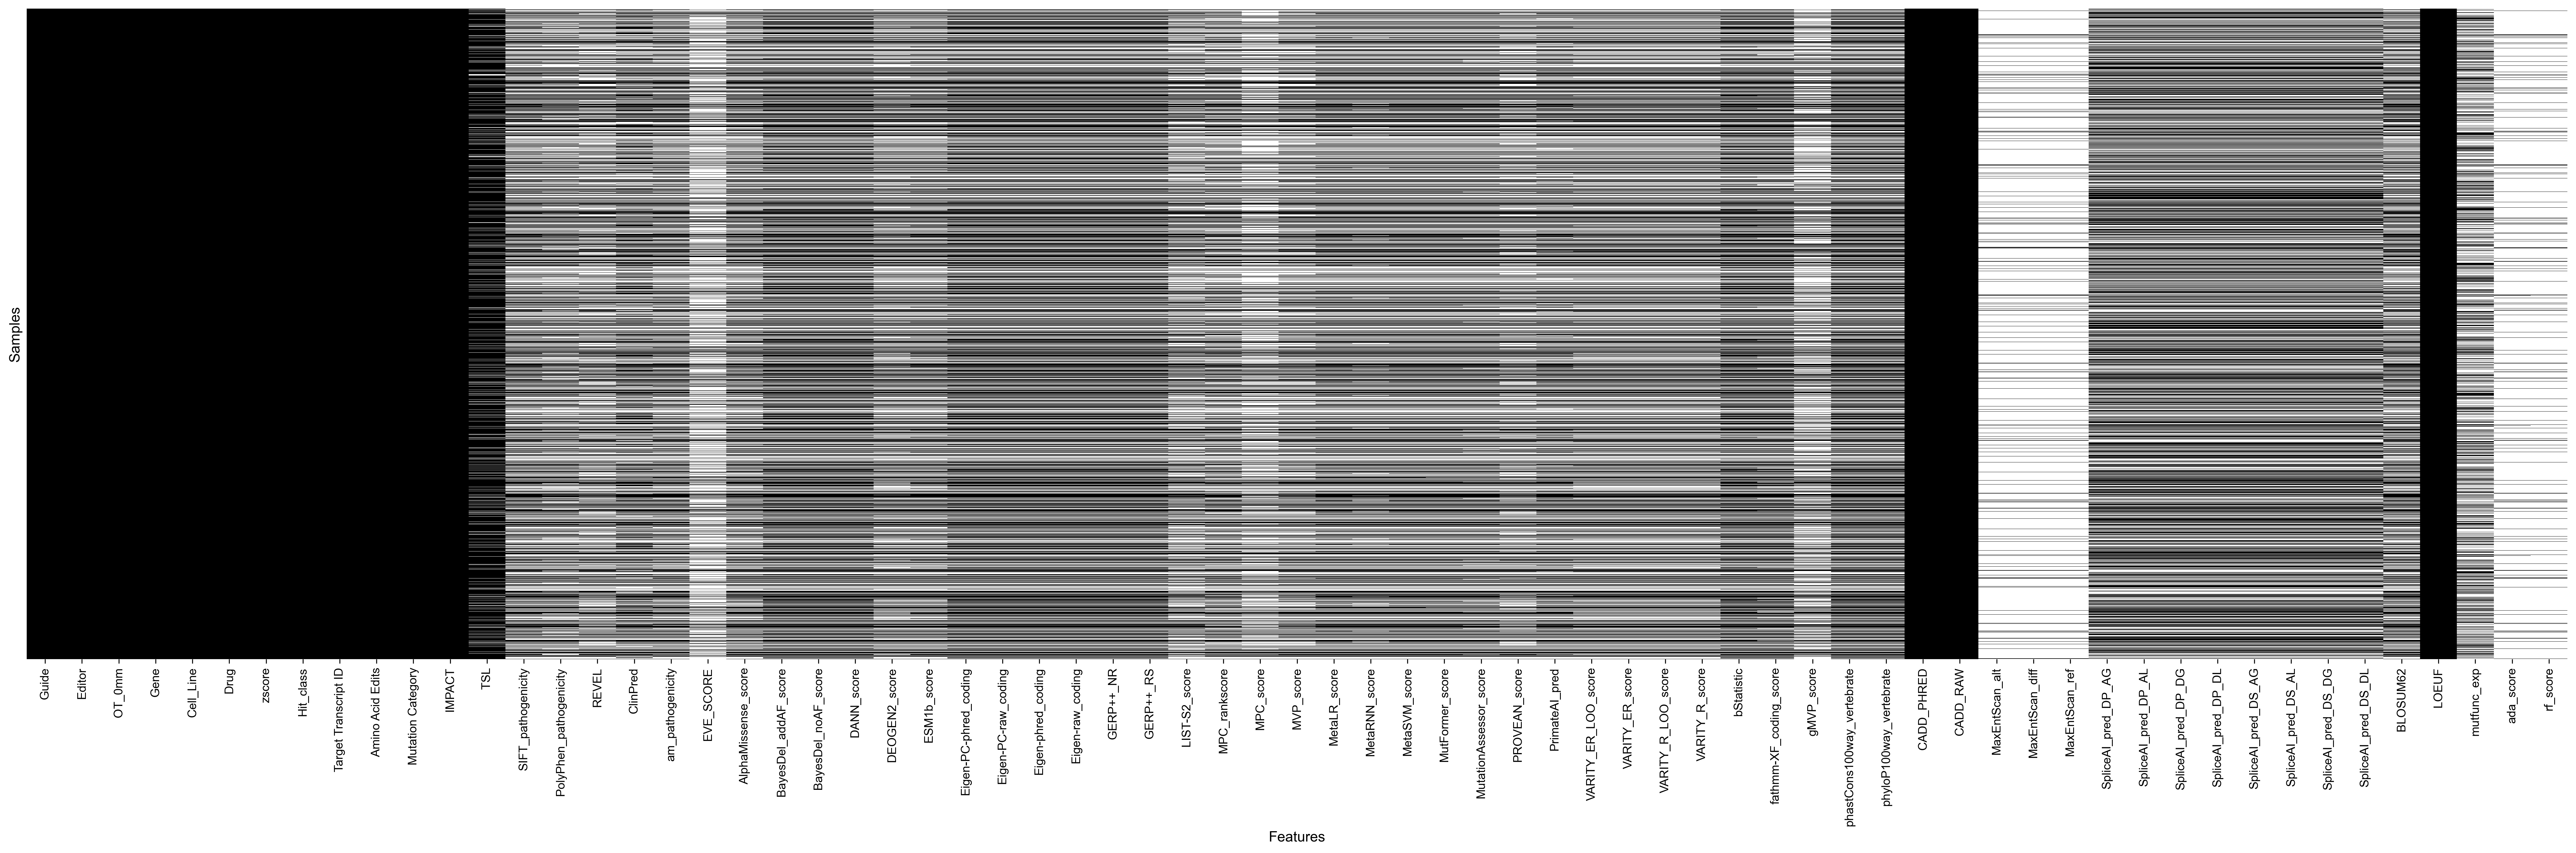

In [42]:
#Heatmap of missing values
plt.figure(figsize=(30, 10))

sns.heatmap(
    zscores_control_unambiguous_VEPannotated_processed.isnull(),
    cbar=False,
    cmap='binary_r'
)

plt.xlabel("Features", fontsize=12)
plt.ylabel("Samples", fontsize=12)
plt.xticks(rotation=90, fontsize=10)
plt.yticks([])  # Hide sample indices
plt.tight_layout()
plt.show()

# Encode Categorical Labels

In [44]:
#for control
zscores_control_unambiguous_VEPannotated_encoded = zscores_control_unambiguous_VEPannotated_processed.copy()

#IMPACT
impact_encoder = OrdinalEncoder(categories=[['MODIFIER', 'LOW', 'MODERATE', 'HIGH']])
zscores_control_unambiguous_VEPannotated_encoded['IMPACT_enc'] = impact_encoder.fit_transform(zscores_control_unambiguous_VEPannotated_encoded[['IMPACT']])

#Mutation Category
mutcat_encoder = OrdinalEncoder(categories=[['Intron', 'UTR', 'Silent', 'Missense', 'Nonsense', 'Splice-acceptor','Splice-donor']])
zscores_control_unambiguous_VEPannotated_encoded['Mutation_Category_enc'] = mutcat_encoder.fit_transform(zscores_control_unambiguous_VEPannotated_encoded[['Mutation Category']])

#PrimateAI_pred
primateAI_encoder = OrdinalEncoder(categories=[['D', 'T']], handle_unknown='use_encoded_value', unknown_value=np.nan)
zscores_control_unambiguous_VEPannotated_encoded['PrimateAI_pred_enc'] = primateAI_encoder.fit_transform(zscores_control_unambiguous_VEPannotated_encoded[['PrimateAI_pred']])

#Reorder the columns
cols_control = zscores_control_unambiguous_VEPannotated_encoded.columns.tolist()
cols_control.insert(cols_control.index('PrimateAI_pred') + 1, cols_control.pop(cols_control.index('PrimateAI_pred_enc')))
cols_control.insert(cols_control.index('Mutation Category') + 1, cols_control.pop(cols_control.index('Mutation_Category_enc')))
cols_control.insert(cols_control.index('IMPACT') + 1, cols_control.pop(cols_control.index('IMPACT_enc')))

zscores_control_unambiguous_VEPannotated_encoded = zscores_control_unambiguous_VEPannotated_encoded[cols_control]

In [45]:
#for control
zscores_control_unambiguous_VEPannotated_encoded = zscores_control_unambiguous_VEPannotated_encoded.drop(columns=['IMPACT', 'Mutation Category', 'PrimateAI_pred'])

In [46]:
zscores_control_unambiguous_VEPannotated_encoded.head()


,Guide,Editor,OT_0mm,Gene,Cell_Line,Drug,zscore,Hit_class,Target Transcript ID,Amino Acid Edits,Mutation_Category_enc,IMPACT_enc,TSL,SIFT_pathogenicity,PolyPhen_pathogenicity,REVEL,ClinPred,am_pathogenicity,EVE_SCORE,AlphaMissense_score,BayesDel_addAF_score,BayesDel_noAF_score,DANN_score,DEOGEN2_score,ESM1b_score,Eigen-PC-phred_coding,Eigen-PC-raw_coding,Eigen-phred_coding,Eigen-raw_coding,GERP++_NR,GERP++_RS,LIST-S2_score,MPC_rankscore,MPC_score,MVP_score,MetaLR_score,MetaRNN_score,MetaSVM_score,MutFormer_score,MutationAssessor_score,PROVEAN_score,PrimateAI_pred_enc,VARITY_ER_LOO_score,VARITY_ER_score,VARITY_R_LOO_score,VARITY_R_score,bStatistic,fathmm-XF_coding_score,gMVP_score,phastCons100way_vertebrate,phyloP100way_vertebrate,CADD_PHRED,CADD_RAW,MaxEntScan_alt,MaxEntScan_diff,MaxEntScan_ref,SpliceAI_pred_DP_AG,SpliceAI_pred_DP_AL,SpliceAI_pred_DP_DG,SpliceAI_pred_DP_DL,SpliceAI_pred_DS_AG,SpliceAI_pred_DS_AL,SpliceAI_pred_DS_DG,SpliceAI_pred_DS_DL,BLOSUM62,LOEUF,mutfunc_exp,ada_score,rf_score
0,AAAAAACATCGTAGTAGCAG,CBE,1.0,RICTOR,A375,PIC,0.238235,non-hit,ENST00000357387.8,His1109Tyr,3.0,2.0,1.0,1.0,0.000,0.214,0.463040,0.0685,NaN,0.0685,-0.114447,-0.402171,0.970933,0.045001,-4.388,5.314964,0.516773,4.111072,0.361058,5.75,5.75,0.917608,0.44121,0.445060,0.093490,0.0689,0.179100,-1.0259,0.000785,0.345,-0.22,1.0,0.157308,0.157308,0.094767,0.094767,226.0,0.800526,NaN,1.000,5.938,20.400,2.813513,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,0.305,NaN,NaN,NaN
1,AAAAAACTCAACAGCAGTGA,CBE,1.0,NRAS,A375,PIC,0.418206,non-hit,ENST00000369535.5,Leu171Phe,3.0,2.0,1.0,0.1,NaN,0.141,0.413488,0.1149,NaN,0.1149,0.010688,-0.222424,0.993713,0.120039,-5.943,3.683551,0.294249,2.801108,0.078205,5.86,5.86,0.865513,0.74516,1.008632,0.619943,0.1053,0.190982,-0.9613,0.907693,1.385,-1.28,1.0,0.106259,0.106259,0.072730,0.072730,819.0,0.580949,0.628916,1.000,4.055,23.400,3.741037,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.550,NaN,NaN,NaN
2,AAAAAACTGGCCAGGTGAGC,CBE,1.0,PIK3CB,A375,PIC,0.371010,non-hit,ENST00000674063.1,Thr930Ile,3.0,2.0,NaN,0.0,0.862,NaN,0.373381,0.7209,NaN,NaN,0.125089,-0.058094,0.998396,0.879846,-10.191,4.891242,0.469329,5.445983,0.549592,5.63,3.78,NaN,0.73854,NaN,NaN,0.7441,NaN,0.6434,0.529280,3.705,NaN,0.0,0.443503,0.443503,0.365695,0.365695,856.0,0.310513,NaN,0.998,2.094,25.400,4.475384,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,0.319,NaN,NaN,NaN
3,AAAAAACTGTTTGGGACCTC,CBE,1.0,EGFR,A375,PIC,-0.876977,non-hit,ENST00000275493.7,Leu480Leu,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.051,0.879011,NaN,NaN,NaN,21.0,-44.0,-45.0,45.0,0.0,0.0,0.0,0.0,NaN,0.475,-0.01879,NaN,NaN
4,AAAAAATCCAGCGTCTAAGC,CBE,1.0,MYC,A375,PIC,-0.454147,non-hit,ENST00000621592.8,Asp2Asn,3.0,2.0,1.0,0.0,0.199,NaN,0.453567,NaN,NaN,0.1399,-0.139436,-0.438067,0.984375,NaN,NaN,1.792897,-0.197017,1.853913,-0.208103,4.31,2.43,0.397160,NaN,NaN,0.733174,0.3185,0.215208,-0.7405,0.036037,NaN,NaN,1.0,NaN,NaN,NaN,NaN,951.0,0.226082,0.128201,1.000,1.507,22.100,3.287154,NaN,NaN,NaN,16.0,-14.0,10.0,26.0,0.0,0.0,0.0,0.0,1.0,0.128,NaN,NaN,NaN


In [47]:
#Check data types 
VEP_info_encoded = pd.DataFrame({
    'dtype': zscores_control_unambiguous_VEPannotated_encoded.dtypes,
    'non-null count': zscores_control_unambiguous_VEPannotated_encoded.notna().sum(),
    'missing (%)': zscores_control_unambiguous_VEPannotated_encoded.isna().mean() * 100,
    'n_unique': zscores_control_unambiguous_VEPannotated_encoded.nunique(),
    'example': zscores_control_unambiguous_VEPannotated_encoded.apply(lambda col: col.dropna().unique()[:3])
}).sort_values('missing (%)', ascending=True)

print(f'{len(zscores_control_unambiguous_VEPannotated_encoded)} rows and {len(zscores_control_unambiguous_VEPannotated_encoded.columns)} columns')
VEP_info_encoded

63285 rows and 69 columns


,dtype,non-null count,missing (%),n_unique,example
Guide,object,63285,0.000000,12657,"[AAAAAACATCGTAGTAGCAG, AAAAAACTCAACAGCAGTGA, A..."
CADD_PHRED,float64,63285,0.000000,2848,"[20.4, 23.4, 25.4]"
LOEUF,float64,63285,0.000000,28,"[0.305, 0.55, 0.319]"
CADD_RAW,float64,63285,0.000000,9493,"[2.813513, 3.741037, 4.475384]"
Mutation_Category_enc,float64,63285,0.000000,7,"[3.0, 2.0, 5.0]"
Amino Acid Edits,object,63285,0.000000,8026,"[His1109Tyr, Leu171Phe, Thr930Ile]"
Target Transcript ID,object,63285,0.000000,28,"[ENST00000357387.8, ENST00000369535.5, ENST000..."
IMPACT_enc,float64,63285,0.000000,4,"[2.0, 1.0, 3.0]"
zscore,float64,63285,0.000000,63152,"[0.2382350673768793, 0.4182056717224319, 0.371..."
Drug,object,63285,0.000000,3,"[PIC, SCH, LIN]"


# Correlation Analysis

In [51]:
# Drop meta columns and create a training fetaures only dataset
training_features_df = zscores_control_unambiguous_VEPannotated_encoded.drop(columns=meta_cols, errors='ignore')

print(f"Shape of feature dataset: {training_features_df.shape}")

Shape of feature dataset: (63285, 60)


In [52]:
#Check data types 
VEP_info_features = pd.DataFrame({
    'dtype': training_features_df.dtypes,
    'non-null count': training_features_df.notna().sum(),
    'missing (%)': training_features_df.isna().mean() * 100,
    'n_unique': training_features_df.nunique(),
    'example': training_features_df.apply(lambda col: col.dropna().unique()[:3])
}).sort_values('missing (%)', ascending=True)

print(f'{len(training_features_df)} rows and {len(training_features_df.columns)} columns')
VEP_info_features

63285 rows and 60 columns


,dtype,non-null count,missing (%),n_unique,example
zscore,float64,63285,0.000000,63152,"[0.2382350673768793, 0.4182056717224319, 0.371..."
Mutation_Category_enc,float64,63285,0.000000,7,"[3.0, 2.0, 5.0]"
IMPACT_enc,float64,63285,0.000000,4,"[2.0, 1.0, 3.0]"
LOEUF,float64,63285,0.000000,28,"[0.305, 0.55, 0.319]"
CADD_PHRED,float64,63285,0.000000,2848,"[20.4, 23.4, 25.4]"
CADD_RAW,float64,63285,0.000000,9493,"[2.813513, 3.741037, 4.475384]"
TSL,float64,54510,13.865845,2,"[1.0, 2.0]"
SpliceAI_pred_DP_DG,float64,35540,43.841353,101,"[-45.0, 10.0, -8.0]"
SpliceAI_pred_DP_DL,float64,35540,43.841353,100,"[45.0, 26.0, -11.0]"
SpliceAI_pred_DS_AG,float64,35540,43.841353,81,"[0.0, 0.04, 0.01]"


In [53]:
# Compute correlation matrix
corr_matrix = training_features_df.corr()
corr_matrix

,zscore,Mutation_Category_enc,IMPACT_enc,TSL,SIFT_pathogenicity,PolyPhen_pathogenicity,REVEL,ClinPred,am_pathogenicity,EVE_SCORE,AlphaMissense_score,BayesDel_addAF_score,BayesDel_noAF_score,DANN_score,DEOGEN2_score,ESM1b_score,Eigen-PC-phred_coding,Eigen-PC-raw_coding,Eigen-phred_coding,Eigen-raw_coding,GERP++_NR,GERP++_RS,LIST-S2_score,MPC_rankscore,MPC_score,MVP_score,MetaLR_score,MetaRNN_score,MetaSVM_score,MutFormer_score,MutationAssessor_score,PROVEAN_score,PrimateAI_pred_enc,VARITY_ER_LOO_score,VARITY_ER_score,VARITY_R_LOO_score,VARITY_R_score,bStatistic,fathmm-XF_coding_score,gMVP_score,phastCons100way_vertebrate,phyloP100way_vertebrate,CADD_PHRED,CADD_RAW,MaxEntScan_alt,MaxEntScan_diff,MaxEntScan_ref,SpliceAI_pred_DP_AG,SpliceAI_pred_DP_AL,SpliceAI_pred_DP_DG,SpliceAI_pred_DP_DL,SpliceAI_pred_DS_AG,SpliceAI_pred_DS_AL,SpliceAI_pred_DS_DG,SpliceAI_pred_DS_DL,BLOSUM62,LOEUF,mutfunc_exp,ada_score,rf_score
zscore,1.000000,0.007752,0.011577,0.012433,-0.004585,0.003895,-0.007252,0.011105,0.014930,0.003605,0.017889,0.003695,0.005150,0.012099,0.005353,-0.009585,0.003561,0.010971,0.002736,0.009322,-0.005720,0.009782,0.003181,-0.002897,0.006554,-0.007570,0.007693,0.012838,0.006394,0.033125,0.003427,0.014979,-0.009883,0.015769,0.016037,0.015685,0.015682,0.030980,0.007067,0.012561,0.008747,0.009951,0.013312,0.012365,-0.023391,0.026184,-0.004958,0.003540,0.004147,0.006117,-0.003746,0.017640,0.024342,0.012033,0.003881,0.007509,-0.016689,-0.006456,0.011252,0.011844
Mutation_Category_enc,0.007752,1.000000,0.902520,0.037507,NaN,NaN,NaN,0.029525,NaN,NaN,NaN,0.580653,0.590603,0.092775,NaN,NaN,0.417157,0.258850,0.531129,0.344303,-0.000218,0.003531,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.002790,-0.432991,NaN,0.023570,-0.004707,0.755087,0.764941,-0.602654,0.726099,-0.057123,0.005576,0.055636,0.050778,-0.045399,0.299900,0.393802,0.065597,0.188488,NaN,-0.032390,0.270039,0.724305,0.783590
IMPACT_enc,0.011577,0.902520,1.000000,0.038996,-0.017333,-0.014436,NaN,0.035430,NaN,NaN,NaN,0.582551,0.592348,0.093490,-0.007092,-0.005196,0.411333,0.256201,0.524523,0.340850,-0.009190,0.002461,-0.001369,NaN,NaN,0.046020,0.015583,0.064952,0.016315,0.019569,NaN,0.019165,0.010453,0.033486,0.033314,0.039180,0.038804,0.004475,-0.439240,0.016939,0.025162,-0.005885,0.876957,0.888265,-0.608579,0.749207,-0.035758,-0.011990,0.080150,0.053638,-0.056428,0.226247,0.301331,0.056235,0.119998,0.026629,-0.039054,0.269828,0.738627,0.784245
TSL,0.012433,0.037507,0.038996,1.000000,0.005795,0.021273,0.070491,0.055177,0.065194,0.005189,0.065950,0.088725,0.079976,0.016221,0.071625,0.045874,0.012984,0.055873,0.006962,0.041426,0.046190,0.068917,0.086448,0.131965,0.160304,0.065882,0.021675,0.071404,0.003807,0.215767,-0.021233,0.014147,-0.142066,0.076926,0.077550,0.097382,0.098016,0.158664,0.018990,0.115463,0.065795,0.089486,0.045506,0.045980,-0.019633,0.041285,0.022907,0.021894,-0.020021,-0.027218,0.004411,-0.006695,0.024845,-0.024792,0.024759,-0.005513,-0.189341,NaN,0.003784,0.019376
SIFT_pathogenicity,-0.004585,NaN,-0.017333,0.005795,1.000000,-0.413066,-0.372942,-0.472791,-0.400844,-0.406947,-0.402475,-0.402940,-0.406670,-0.461490,-0.360302,0.367032,-0.396059,-0.512775,-0.410041,-0.541350,0.006869,-0.289036,-0.371658,-0.406196,-0.369995,-0.294334,-0.324123,-0.482491,-0.336739,-0.248012,-0.440257,0.416958,0.255298,-0.389397,-0.389236,-0.394241,-0.394308,-0.003309,-0.506276,-0.386182,-0.275220,-0.409626,-0.557045,-0.596549,0.126308,-0.045129,0.132828,-0.013775,0.044866,0.018212,0.015369,-0.005362,-0.010611,0.080338,0.018665,0.158103,0.070990,-0.101232,-0.127166,-0.225195
PolyPhen_pathogenicity,0.003895,NaN,-0.014436,0.021273,-0.413066,1.000000,0.651217,0.553038,0.643354,0.734138,0.634752,0.578770,0.586277,0.277154,0.518146,-0.559612,0.718322,0.662963,0.763529,0.745147,-0.000492,0.251407,0.389951,0.582097,0.582716,0.382382,0.555937,0.726814,0.593127,0.247336,0.564121,-0.625255,-0.318167,0.672332,0.672278,0.653651,0.653629,0.033523,0.499545,0.595674,0.243851,0.435

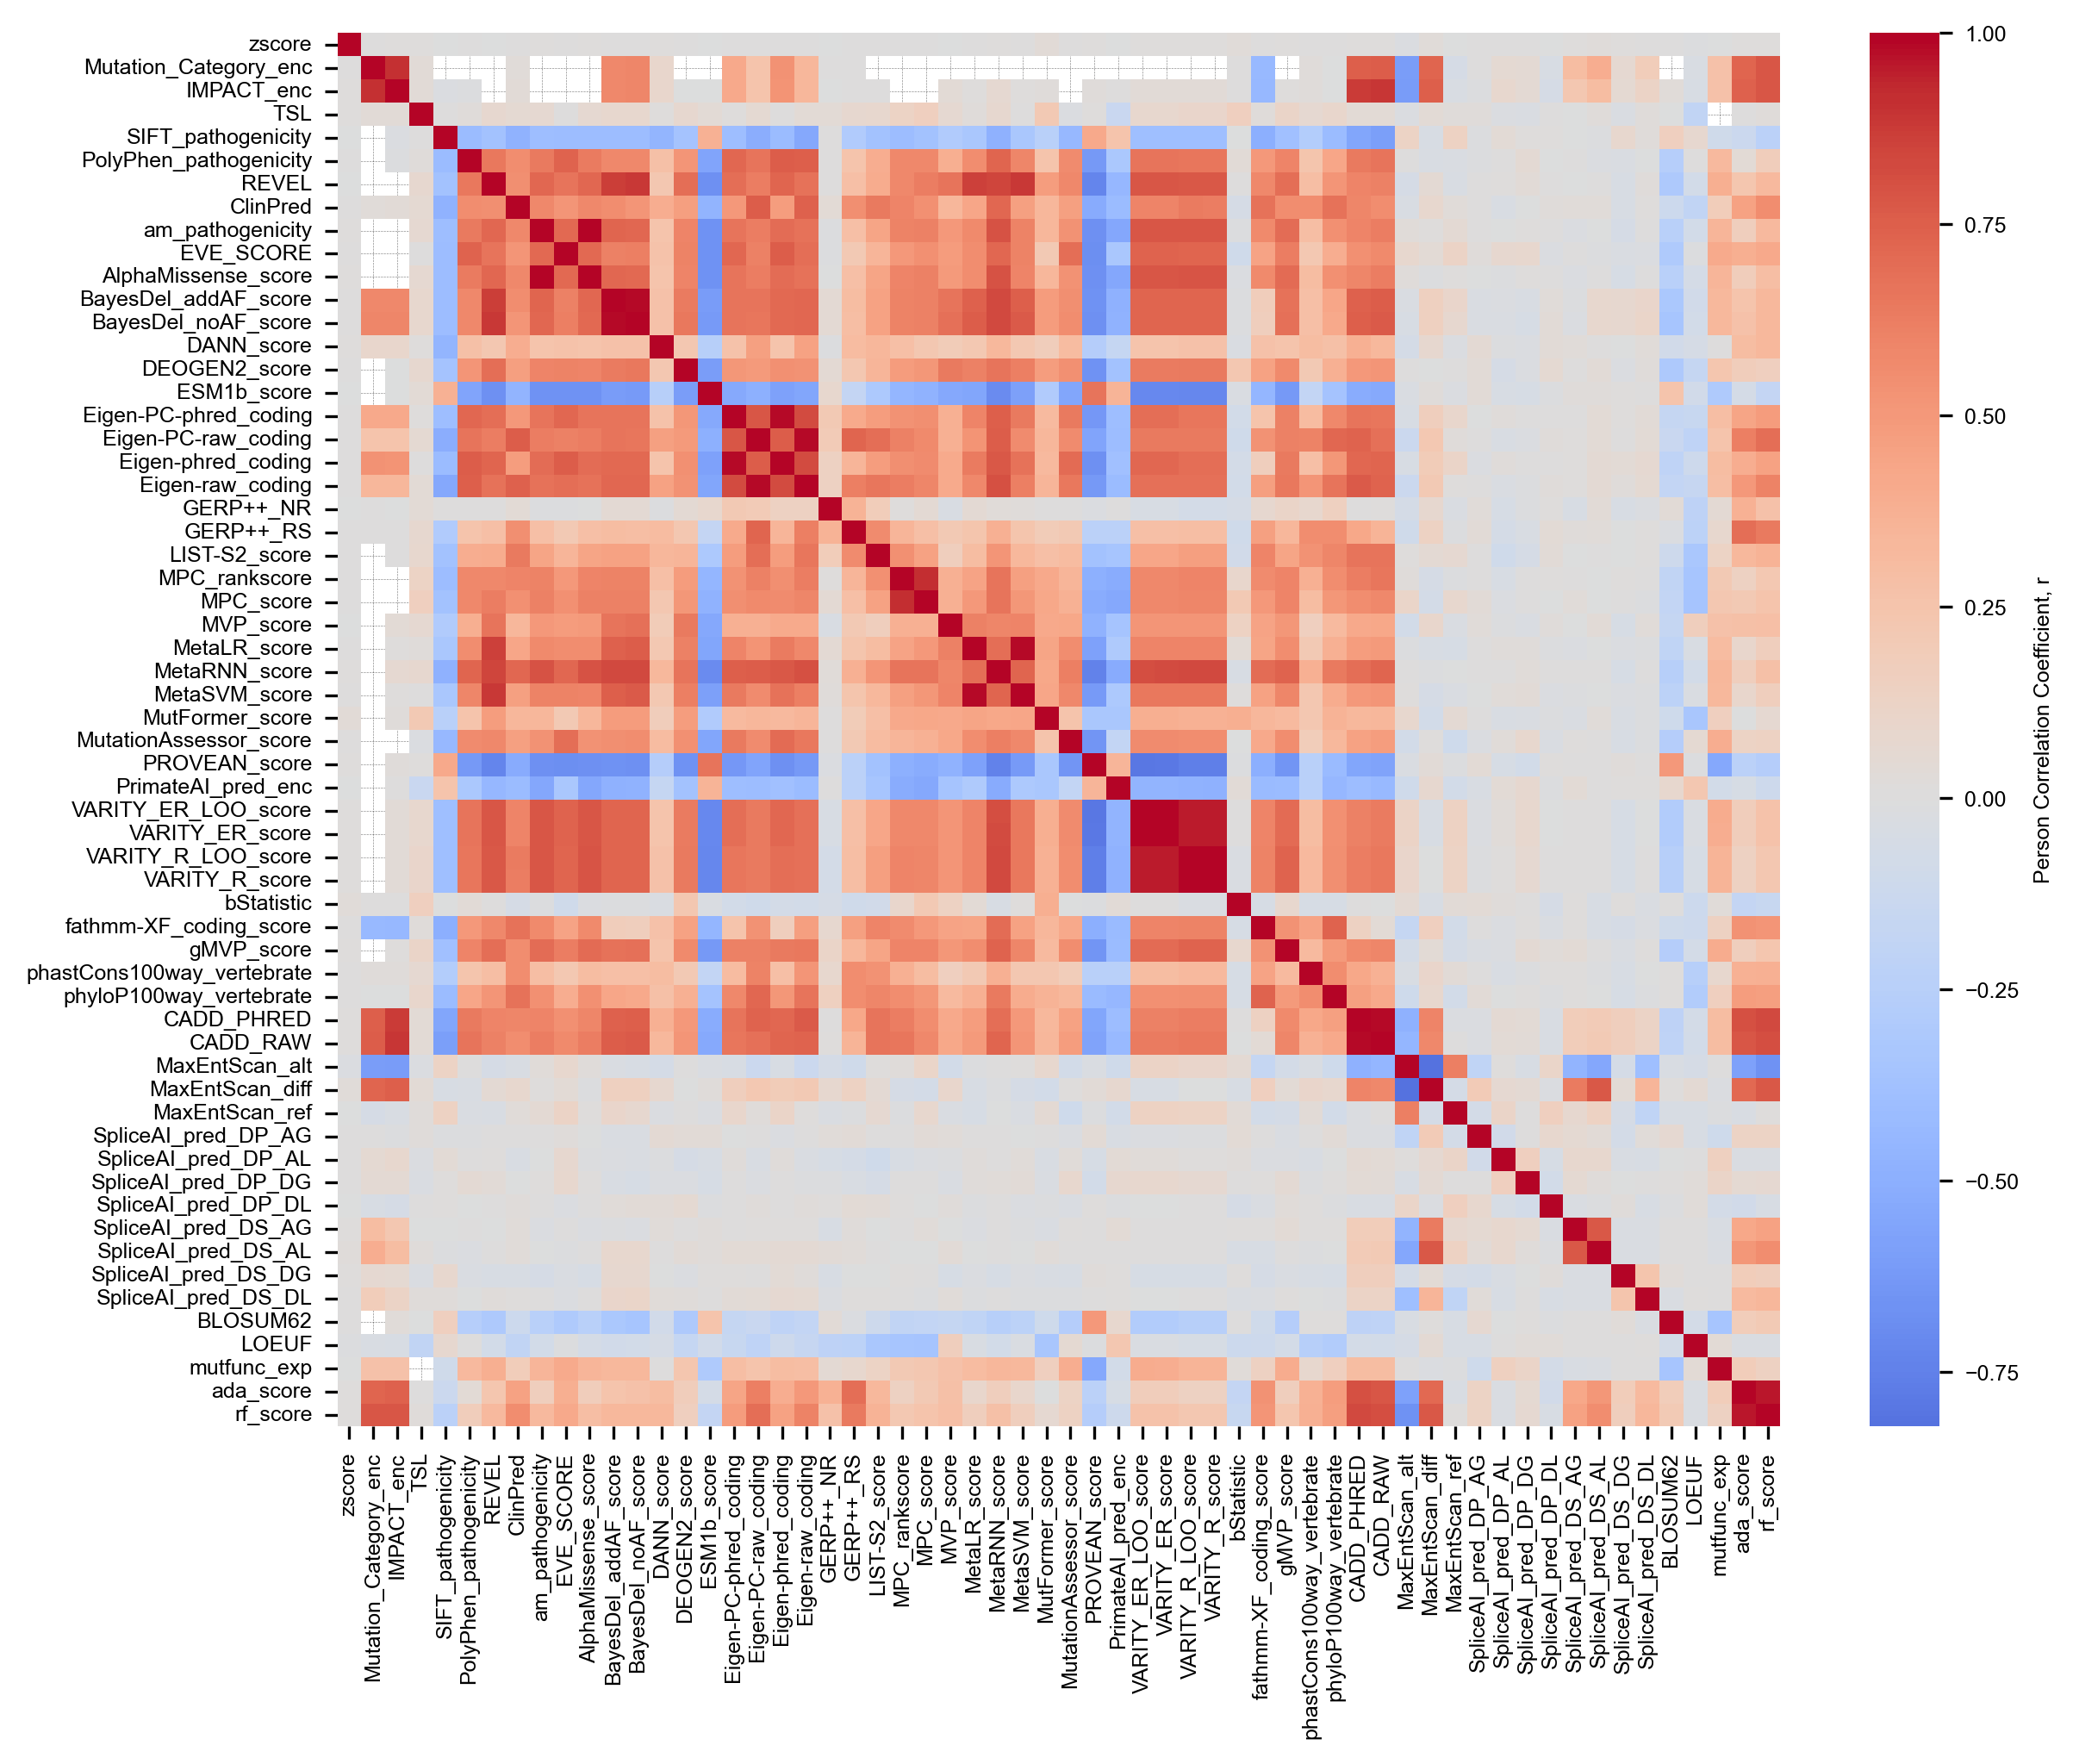

In [54]:
# Plot heatmap
plt.figure(figsize=(9,7))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, cbar_kws={'label': 'Person Correlation Coefficient, r'})
plt.show()

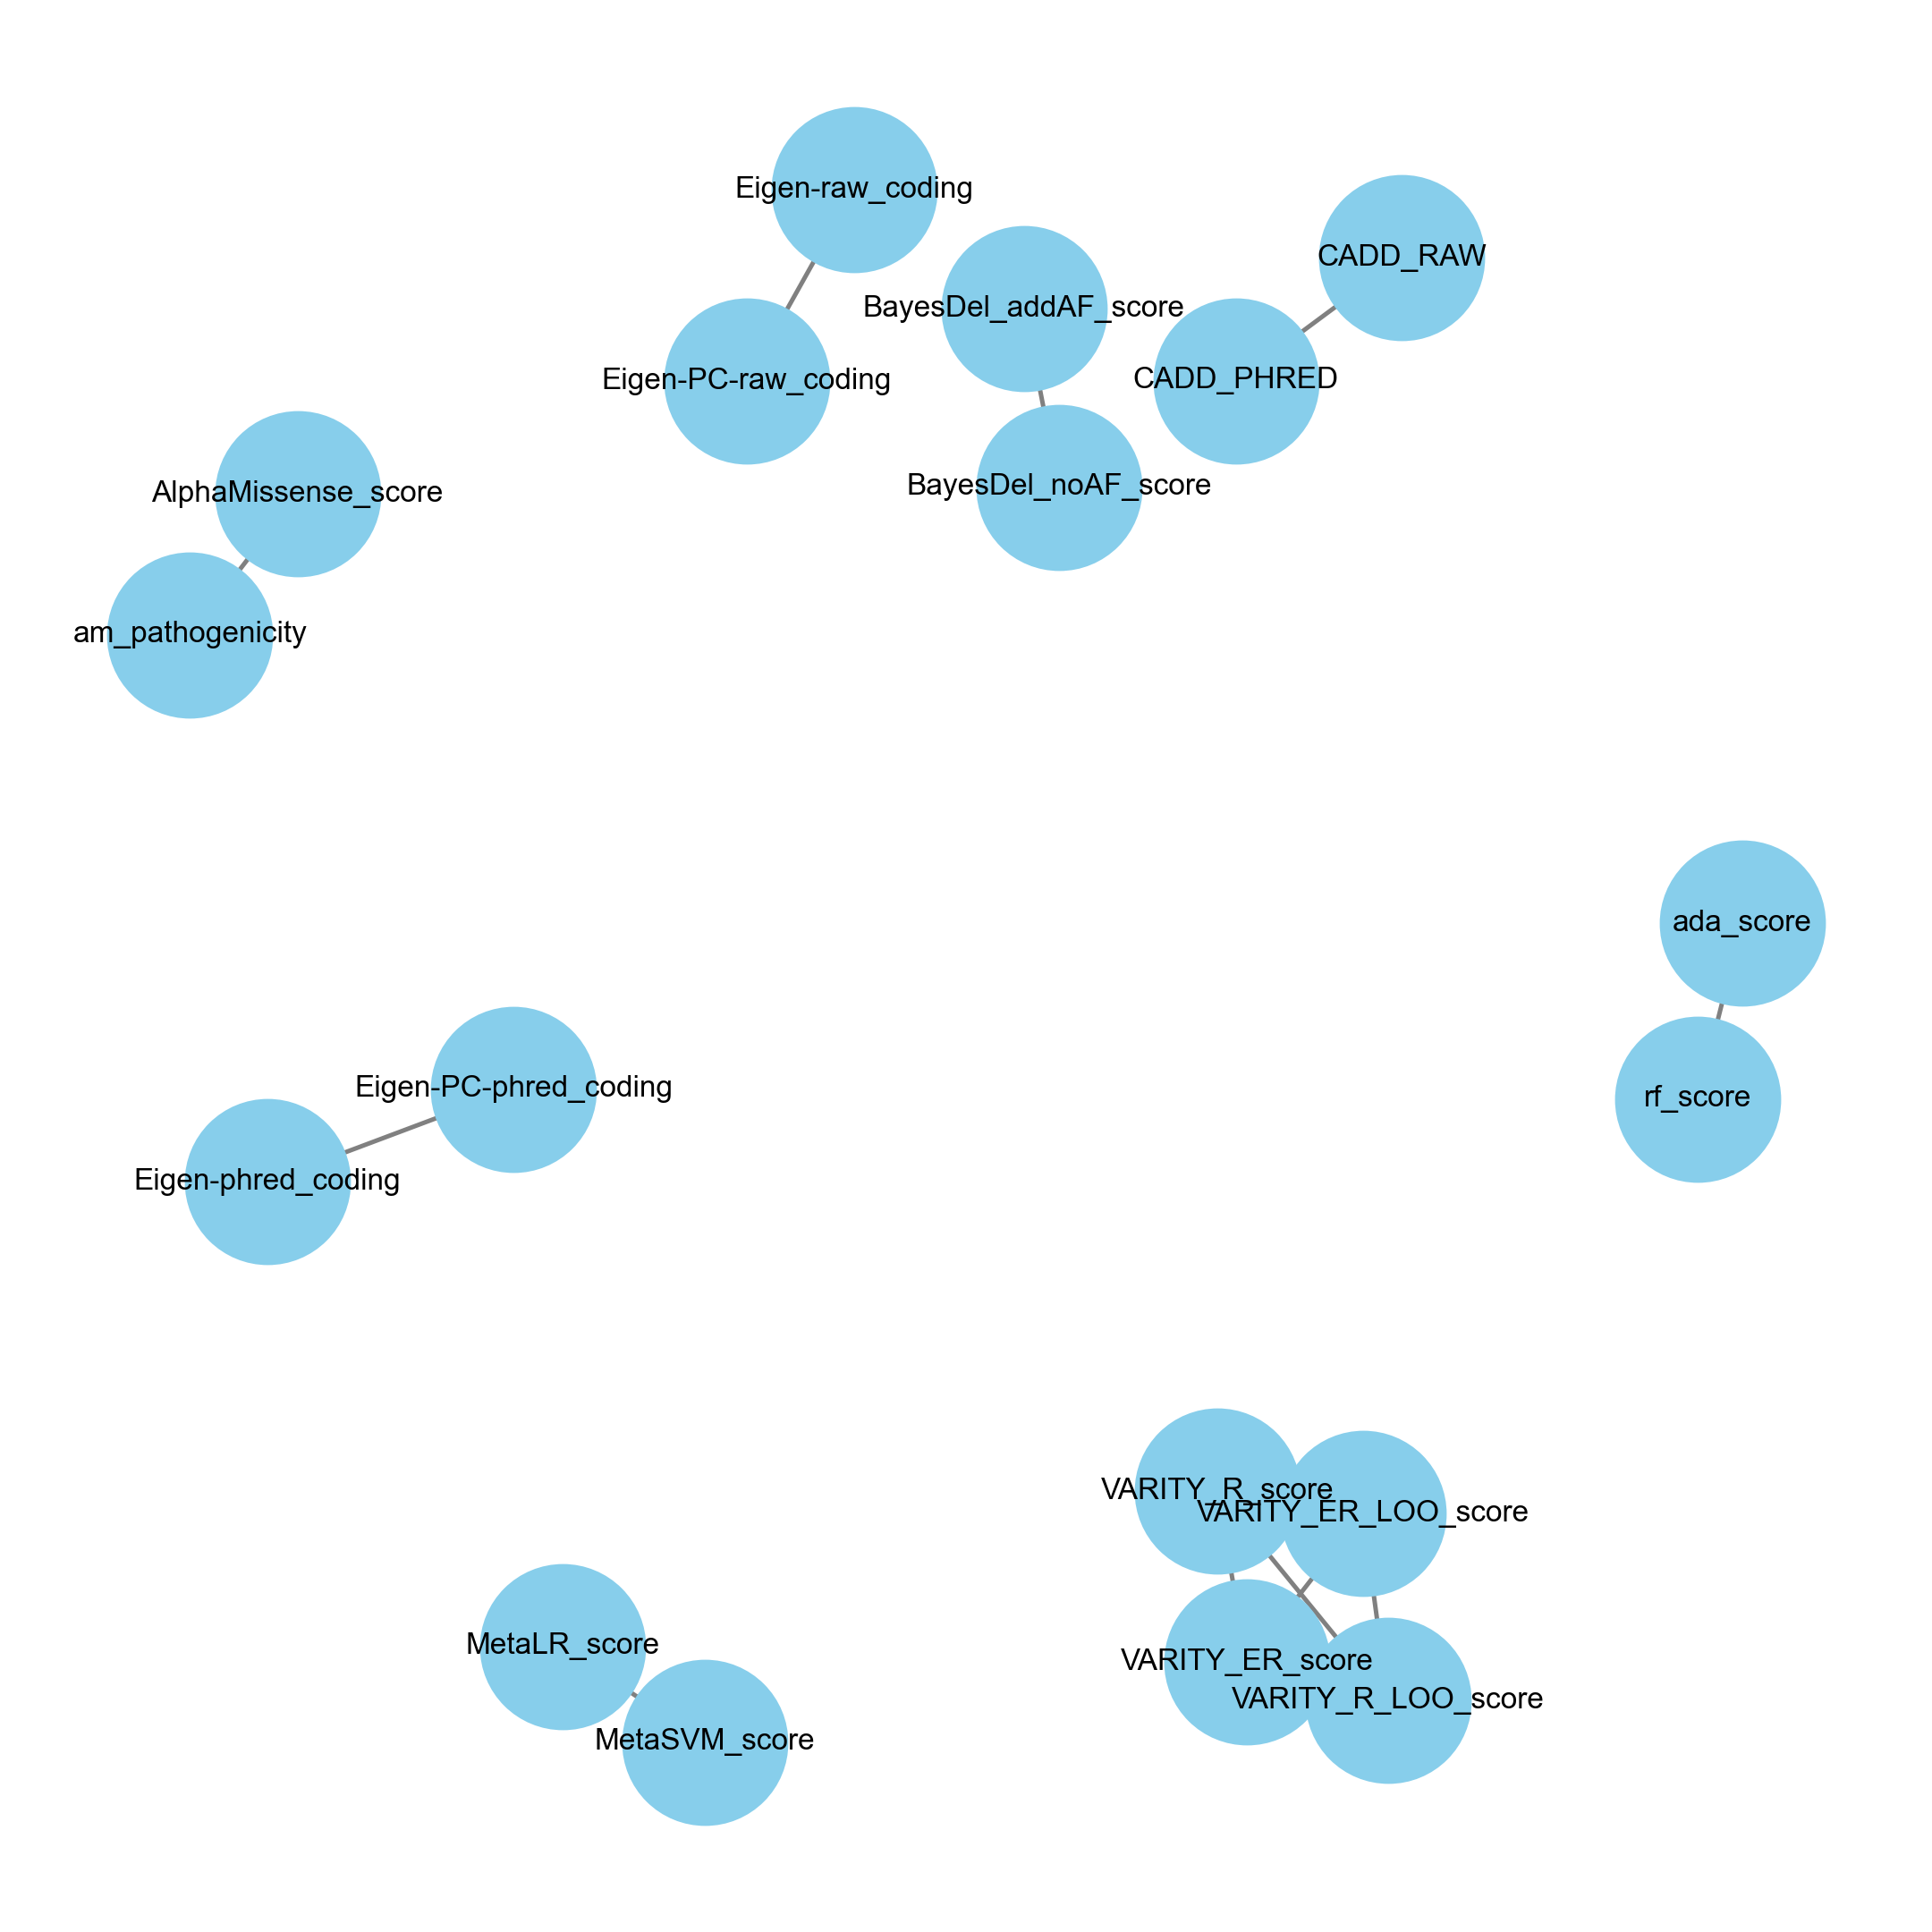

In [55]:
import networkx as nx

threshold = 0.95
G = nx.Graph()

# Add edges for highly correlated pairs
for col in corr_matrix.columns:
    for row in corr_matrix.index:
        if col != row and abs(corr_matrix.loc[row, col]) > threshold:
            G.add_edge(col, row, weight=corr_matrix.loc[row, col])

plt.figure(figsize=(7,7))
pos = nx.spring_layout(G, k=1.1, iterations=100) 
nx.draw(
    G, pos,
    with_labels=True,
    node_size=1900,
    font_size=8,
    font_weight="normal",
    node_color="skyblue",
    edge_color="gray",
    width=1.2
)

#plt.title("Correlation Network Graph (>0.9)")
plt.show()

In [56]:
columns_to_drop_corr = [
    'AlphaMissense_score', 
    'CADD_RAW',
    'BayesDel_addAF_score',
    'MetaLR_score',
    'VARITY_ER_score',
    'VARITY_ER_LOO_score',
    'VARITY_R_score',
    'Eigen-raw_coding',
    'Eigen-phred_coding',
    'rf_score'
]
#Drop the correlated (>0.95) columns for control
zscores_control_unambiguous_VEPannotated_encoded = (zscores_control_unambiguous_VEPannotated_encoded.drop(columns=columns_to_drop_corr))
print(f"Shape after dropping correlated columns for control: {zscores_control_unambiguous_VEPannotated_encoded.shape}")

Shape after dropping correlated columns for control: (63285, 59)


In [57]:
zscores_control_unambiguous_VEPannotated_encoded.head()

,Guide,Editor,OT_0mm,Gene,Cell_Line,Drug,zscore,Hit_class,Target Transcript ID,Amino Acid Edits,Mutation_Category_enc,IMPACT_enc,TSL,SIFT_pathogenicity,PolyPhen_pathogenicity,REVEL,ClinPred,am_pathogenicity,EVE_SCORE,BayesDel_noAF_score,DANN_score,DEOGEN2_score,ESM1b_score,Eigen-PC-phred_coding,Eigen-PC-raw_coding,GERP++_NR,GERP++_RS,LIST-S2_score,MPC_rankscore,MPC_score,MVP_score,MetaRNN_score,MetaSVM_score,MutFormer_score,MutationAssessor_score,PROVEAN_score,PrimateAI_pred_enc,VARITY_R_LOO_score,bStatistic,fathmm-XF_coding_score,gMVP_score,phastCons100way_vertebrate,phyloP100way_vertebrate,CADD_PHRED,MaxEntScan_alt,MaxEntScan_diff,MaxEntScan_ref,SpliceAI_pred_DP_AG,SpliceAI_pred_DP_AL,SpliceAI_pred_DP_DG,SpliceAI_pred_DP_DL,SpliceAI_pred_DS_AG,SpliceAI_pred_DS_AL,SpliceAI_pred_DS_DG,SpliceAI_pred_DS_DL,BLOSUM62,LOEUF,mutfunc_exp,ada_score
0,AAAAAACATCGTAGTAGCAG,CBE,1.0,RICTOR,A375,PIC,0.238235,non-hit,ENST00000357387.8,His1109Tyr,3.0,2.0,1.0,1.0,0.000,0.214,0.463040,0.0685,NaN,-0.402171,0.970933,0.045001,-4.388,5.314964,0.516773,5.75,5.75,0.917608,0.44121,0.445060,0.093490,0.179100,-1.0259,0.000785,0.345,-0.22,1.0,0.094767,226.0,0.800526,NaN,1.000,5.938,20.400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,0.305,NaN,NaN
1,AAAAAACTCAACAGCAGTGA,CBE,1.0,NRAS,A375,PIC,0.418206,non-hit,ENST00000369535.5,Leu171Phe,3.0,2.0,1.0,0.1,NaN,0.141,0.413488,0.1149,NaN,-0.222424,0.993713,0.120039,-5.943,3.683551,0.294249,5.86,5.86,0.865513,0.74516,1.008632,0.619943,0.190982,-0.9613,0.907693,1.385,-1.28,1.0,0.072730,819.0,0.580949,0.628916,1.000,4.055,23.400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.550,NaN,NaN
2,AAAAAACTGGCCAGGTGAGC,CBE,1.0,PIK3CB,A375,PIC,0.371010,non-hit,ENST00000674063.1,Thr930Ile,3.0,2.0,NaN,0.0,0.862,NaN,0.373381,0.7209,NaN,-0.058094,0.998396,0.879846,-10.191,4.891242,0.469329,5.63,3.78,NaN,0.73854,NaN,NaN,NaN,0.6434,0.529280,3.705,NaN,0.0,0.365695,856.0,0.310513,NaN,0.998,2.094,25.400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,0.319,NaN,NaN
3,AAAAAACTGTTTGGGACCTC,CBE,1.0,EGFR,A375,PIC,-0.876977,non-hit,ENST00000275493.7,Leu480Leu,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.051,NaN,NaN,NaN,21.0,-44.0,-45.0,45.0,0.0,0.0,0.0,0.0,NaN,0.475,-0.01879,NaN
4,AAAAAATCCAGCGTCTAAGC,CBE,1.0,MYC,A375,PIC,-0.454147,non-hit,ENST00000621592.8,Asp2Asn,3.0,2.0,1.0,0.0,0.199,NaN,0.453567,NaN,NaN,-0.438067,0.984375,NaN,NaN,1.792897,-0.197017,4.31,2.43,0.397160,NaN,NaN,0.733174,0.215208,-0.7405,0.036037,NaN,NaN,1.0,NaN,951.0,0.226082,0.128201,1.000,1.507,22.100,NaN,NaN,NaN,16.0,-14.0,10.0,26.0,0.0,0.0,0.0,0.0,1.0,0.128,NaN,NaN


In [58]:
zscores_control_unambiguous_VEPannotated_encoded.to_csv("data/6_VEP/zscores-unambiguous-VEPannotated-processed-control-newversion.csv", index=False)